# Transformer Asset Imputation - Experimental Notebook

This notebook implements the synthetic transformer imputation study: dataset exploration, method evaluation, controlled data-quality interventions, per-attribute analyses, figures, and exported results. **All methods except TabPFN** are run here; TabPFN is evaluated separately.

**Research questions**

- **RQ1:** How do imputation approaches compare on numerical and categorical attributes?
- **RQ2:** How does reconstruction change with missingness, measurement noise, grouped missingness, incorrect observed inputs, and training/application mismatch?
- **RQ3:** Which known generator relationships, redundant predictors, and model behaviours help explain the observed results?

The data are **synthetic**, not operational SA Power Networks records. The generator has exact structural relationships and an installation-date/grid shortcut; interpret results within this synthetic population. Numerical accuracy is evaluated on deliberately masked cells, and the joint-table and unseen-record protocols are presented separately.

**How to run:** Use the **Settings** cell to choose `MODE='quick'` for a small complete run or `MODE='full'` for the full study. `EXECUTE_EXPERIMENTS=True` fits the methods on the supplied scenarios and saves a new timestamped run. `EXECUTE_EXPERIMENTS=False` loads a completed run for figure generation and analysis. Relationship experiments can also be selected independently. See `TRANSFORMER_EXPERIMENT_GUIDE.md` at the pipeline root for full installation and reproducibility instructions.

**Method distinction:** Original MissForest and Predictive MissForest share the iterative conditional Random Forest reconstruction mechanism under matched settings. Original MissForest uses convergence-based stopping in a joint-table workflow; Predictive MissForest saves per-pass models and applies them to unseen records with fixed passes. The contribution of the predictive implementation is its reusable inference protocol, not a new forest-learning algorithm.


## 1 - Imports and project paths

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
from contextlib import contextmanager
from dataclasses import asdict
import gc, json, sys, os, warnings, hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Works when Jupyter starts from the pipeline root OR the notebook's directory.
def find_pipeline(start=Path.cwd()):
    for parent in (start, *start.parents):
        if (parent/'experiment/transformer/dataset').is_dir() and (parent/'src/imputation').is_dir():
            return parent
        if (parent/'pipeline/experiment/transformer/dataset').is_dir():
            return parent/'pipeline'
    raise FileNotFoundError('Open this notebook inside the extracted pipeline folder')

PIPELINE = find_pipeline().resolve()
EXP = PIPELINE/'experiment'/'transformer'
DATA = EXP/'dataset'
for item in (PIPELINE, EXP/'scripts', EXP):
    if str(item) not in sys.path:
        sys.path.insert(0,str(item))

from comparison_models import ModelSpec, MedianMode, ChainedConditionalImputer
from src.imputation.predictive_missforest.predictive_missforest import PredictiveMissForest, PredictiveMissForestConfig
from src.imputation.registry import LegacyMissForestImputer
from src.imputation.missforest.missforest import MissForestConfig
from mice_pmm_logistic import Schema, MICEPMMLogistic, aggregate_imputations

print('Pipeline:', PIPELINE)
print('Python:', sys.version.split()[0])
print('Data directory:', DATA)

Pipeline: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline
Python: 3.12.7
Data directory: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/experiment/transformer/dataset


## 2 - Settings (only edit this cell)

In [2]:
# Quick: 1,000 fitting + 1,000 test records with reduced estimator sizes.
# Full: 8,000 fitting + 2,000 test records, proper research hyperparameters.
MODE = 'full'               # 'quick' for setup testing; 'full' for full research experiments
EXECUTE_EXPERIMENTS = True    # True: run experiments; False: analyse a saved run
RUN_RELATIONSHIP_EXPERIMENTS = True   # Joint ablation, volume controls and conditional life analysis
RUN_JOINT_MODEL_ID_ABLATION = True
RUN_T4_VOLUME_CONTROLS = True
RUN_LIFE_HAZARD_TEST = True
RUN_MICE_POOLING_COMPARISON = False  # Used when analysing saved runs; fresh T2 already includes both aggregations
RUN_COMMON_CELL_ANALYSIS = True
VOLUME_CONTROL_SEEDS = [241, 251, 261, 271, 281]
MICE_POINT_REDUCER = 'median'  # Compute median and mean estimates from the same MICE draws; report mean as primary
RUN_SUPERVISED_REFERENCES = False  # Optional, labelled empirical comparators; not upper bounds
RESULTS_SOURCE_DIR = None  # When EXECUTE_EXPERIMENTS=False: a saved run path; None finds the newest full run
RUN_T2 = True
RUN_T3 = True
RUN_T4 = True
RUN_T5 = True
RUN_T6 = True

# One notebook runs all these methods; original MissForest and MICE-PMM are joint-table only.
INDUCTIVE_METHODS = ['median_mode','predictive_missforest','chained_ridge','lightgbm_chained']
JOINT_METHODS = ['median_mode','missforest','predictive_missforest','chained_ridge','lightgbm_chained','mice_pmm_logistic']
T3_METHODS = ['predictive_missforest','chained_ridge','lightgbm_chained']

# Full T2 runs 3 missingness × 3 noise amplitudes × all selected compatible methods.
MASK_RATES = [0.10,0.20,0.30]
NOISE_AMPLITUDES = [0.00,0.05,0.10]
SPLIT_SEED = 617
MODEL_SEED = 219

# Main anchor shared by T3, T4, T5 and T6.
ANCHOR_MASK = .20
ANCHOR_NOISE = .05
ABLATIONS = {
    'all_attributes': [],
    'without_coordinates': ['x','y'],
    'without_install_date': ['install_date'],
    'without_model_id': ['model_id'],
    'without_total_gas': ['total_gas'],
    'without_altitude': ['altitude'],
    'without_placebo': ['random_placebo'],
}
# Primary T4: fixed model, target mask unchanged, supporting predictors hidden on target-missing records.
# Secondary T4: count-preserving group masks, constructed from synthetic truth + synthetic noise,
#                 with refitting; this is a separate experiment and not the primary treatment.
T4_GROUPS = {
    'gas': ('measured_gas_a', ['measured_gas_b','measured_gas_c']),
    'coordinates': ('altitude', ['x','y']),
    'environment': ('measured_humid', ['measured_salt','measured_overgrowth']),
}
T4_COUNT_PRESERVING = True
T4_RUN_JOINT = False  # True only if a separate transductive T4 comparison is needed

T5_PREDICTORS = ['model_id','install_date']
T5_PREVALENCE = [0.00,0.05,0.10,0.25,0.50]
T5_TRAIN_CORRUPTION = True     # Separate fitted-model training corruption at 25% model_id swaps
T5_JOINT_REFIT = False        # Optional, costly, not comparable to frozen-model protocol

T6_TRAIN_NOISE = [0.00,0.05,0.10]
T6_APPLY_NOISE = [0.00,0.05,0.10,0.20,0.40]
T6_MISSINGNESS_MISMATCH = True

# Full-run parameters used for the transformer experiment.
N_TREES = 100 if MODE=='full' else 10
PMF_PASSES = 5 if MODE=='full' else 1
MF_MAX_ITER = 20 if MODE=='full' else 2
CHAIN_PASSES = 3 if MODE=='full' else 1
MICE_CHAINS = 5 if MODE=='full' else 1
MICE_ITERATIONS = 10 if MODE=='full' else 1
BOOTSTRAP_RESAMPLES = 2000 if MODE=='full' else 200
SAVE_CELL_PREDICTIONS = True
SAVE_FROZEN_MODELS = False     # True saves new fits for use across sessions; saved fitted models are optional

RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S')
# Every fresh execution produces its own output directory.
# Saved-run analysis reads the source directory and writes derived files separately.
if EXECUTE_EXPERIMENTS:
    RUN_DIR = EXP/'outputs'/f'transformer_study_{RUN_ID}_{MODE}'
    REPORT_DIR = RUN_DIR
else:
    if RESULTS_SOURCE_DIR is not None:
        RUN_DIR = Path(RESULTS_SOURCE_DIR)
        if not RUN_DIR.is_absolute():
            RUN_DIR = PIPELINE/RUN_DIR
    else:
        prior = sorted(list((EXP/'outputs').glob('transformer_study_*_full')) +
                       list((EXP/'outputs').glob('single_notebook_*_full')),
                       key=lambda folder: folder.stat().st_mtime)
        if not prior:
            raise FileNotFoundError('No completed results found. Set EXECUTE_EXPERIMENTS=True to run experiments.')
        RUN_DIR = prior[-1]
    if not (RUN_DIR/'all_per_target_metrics.csv').is_file():
        raise FileNotFoundError(f'No results table in {RUN_DIR}; select a completed run or execute experiments.')
    REPORT_DIR = EXP/'outputs'/f'transformer_analysis_{RUN_ID}_{MODE}'
REPORT_DIR.mkdir(parents=True,exist_ok=True)
FIG_DIR = REPORT_DIR/'figures'
FIG_DIR.mkdir(exist_ok=True)
print('MODE:', MODE, 'READ:', RUN_DIR, 'NEW OUTPUTS:', REPORT_DIR)

MODE: full READ: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/experiment/transformer/outputs/transformer_study_20261114_133250_full NEW OUTPUTS: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/experiment/transformer/outputs/transformer_study_20261114_133250_full


## 3 - T1: Synthetic Dataset Characterisation and Relationship Analysis

**Objective:** Characterise the synthetic transformer dataset and identify the
attribute relationships that underpin subsequent imputation experiments.

This experiment examines:

- Dataset size, attribute types and descriptive statistics.
- Numerical distributions and categorical attributes.
- Missing-value frequencies and patterns.
- Correlations between numerical attributes.
- Known deterministic and probabilistic generator relationships.
- Synthetic generator characteristics and potential predictive shortcuts.

T1 provides the descriptive foundation for T2–T6. It does not involve
imputation model training or model-performance comparison.## 3 - Load data and explore the generator relationships

In [3]:
NUMERIC = ['x','y','install_date','altitude','measured_humid','measured_salt',
           'measured_overgrowth','life','random_placebo','measured_gas_a',
           'measured_gas_b','measured_gas_c','total_gas','leakage']
CATEGORICAL = ['model_id']
COLUMNS = ['x','y','install_date','model_id','altitude','measured_humid',
           'measured_salt','measured_overgrowth','life','random_placebo',
           'measured_gas_a','measured_gas_b','measured_gas_c','total_gas','leakage']
NOISY = ['measured_humid','measured_salt','measured_overgrowth','random_placebo',
         'measured_gas_a','measured_gas_b','measured_gas_c']

# These are supplied generator scenarios. Load without cleaning, scaling or regenerating.
def pair(mask_rate=.20, noise=.05):
    completion = round(1-float(mask_rate),1)
    noise = round(float(noise),2)
    basename = f'completion{completion:.1f}-noise{noise}'
    a = pd.read_csv(DATA/f'{basename}-measured.csv')[COLUMNS]
    t = pd.read_csv(DATA/f'{basename}-truth.csv')[COLUMNS]
    for frame in (a,t):
        frame['model_id']=frame['model_id'].map(lambda x: str(int(x)) if pd.notna(x) else np.nan)
    return a,t

measured, truth = pair(ANCHOR_MASK, ANCHOR_NOISE)
profile = pd.DataFrame({'dtype': measured.dtypes.astype(str),
                        'missing': measured.isna().sum(),
                        'missing_rate': measured.isna().mean(),
                        'distinct_observed': measured.nunique(dropna=True)})
display(profile)
print('shape:',measured.shape, 'hidden cells:',int(measured.isna().sum().sum()))
print('Known identities in complete generator: altitude = x+y+100; total_gas = gas_a+gas_b+gas_c.')
print('Generator shortcut: coordinate/grid order is strongly related to install_date.')

,dtype,missing,missing_rate,distinct_observed
x,float64,1990,0.1990,100
y,float64,1980,0.1980,100
install_date,float64,1973,0.1973,992
model_id,str,1965,0.1965,4
altitude,float64,2011,0.2011,199
measured_humid,float64,1984,0.1984,8016
measured_salt,float64,1972,0.1972,8028
measured_overgrowth,float64,1959,0.1959,5455
life,float64,1958,0.1958,8042
random_placebo,float64,2011,0.2011,7989


shape: (10000, 15) hidden cells: 29928
Known identities in complete generator: altitude = x+y+100; total_gas = gas_a+gas_b+gas_c.
Generator shortcut: coordinate/grid order is strongly related to install_date.


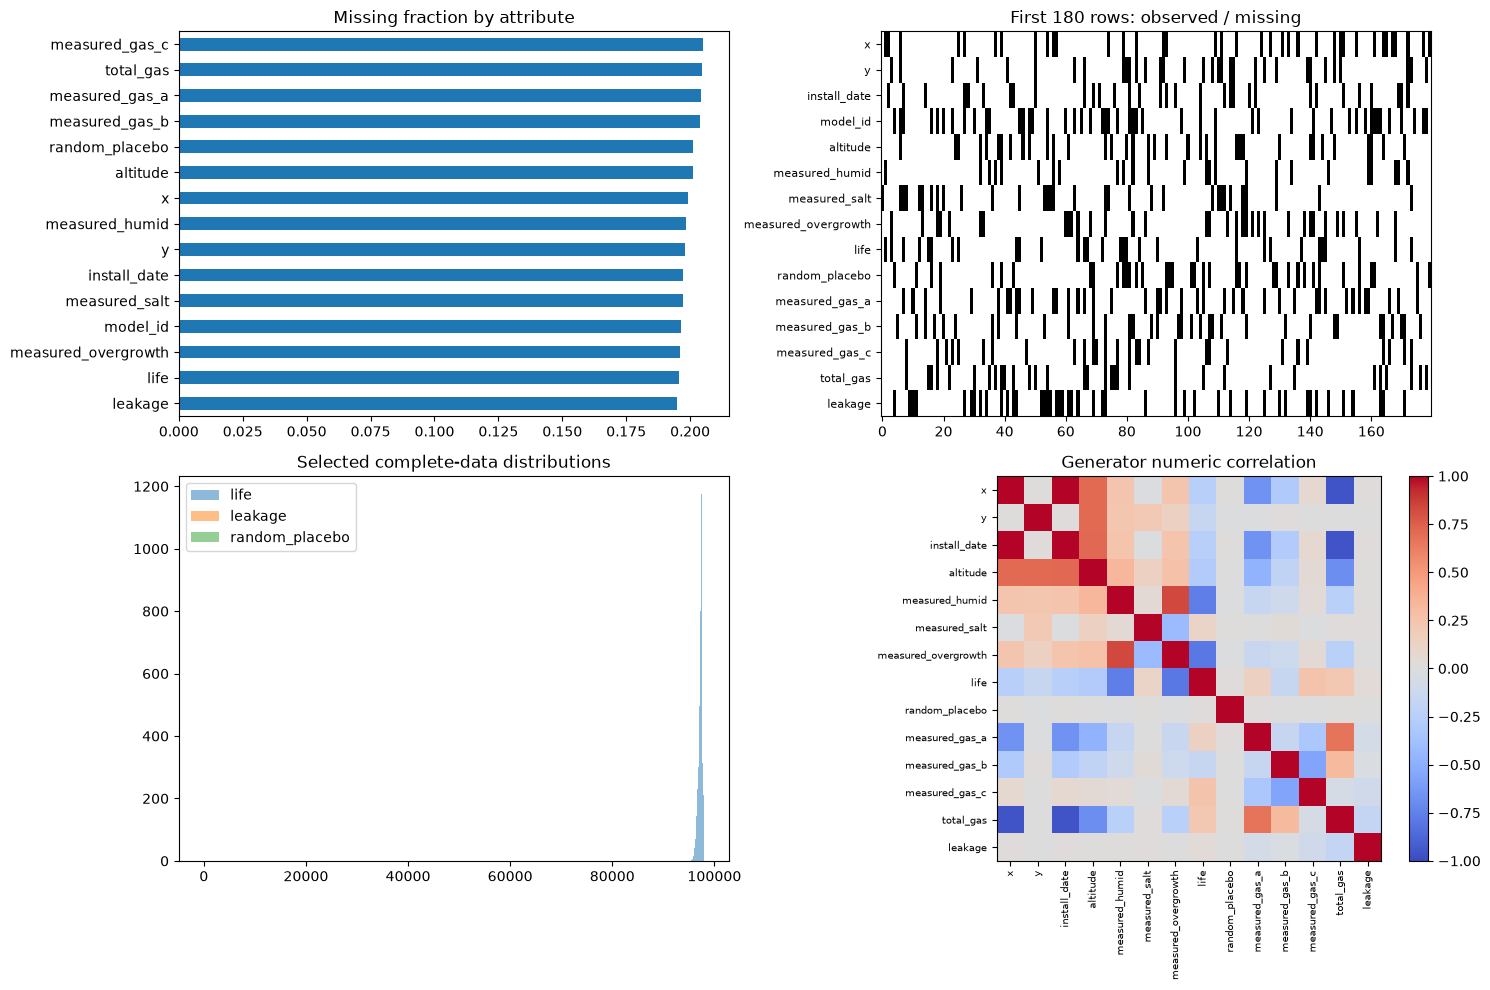

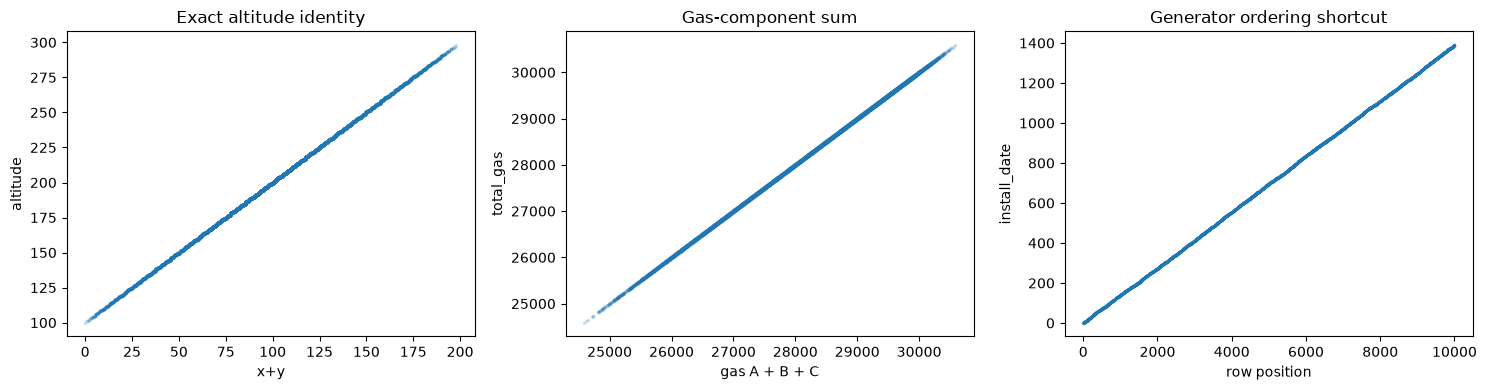

In [4]:
# EDA: distributions, missingness, correlation and synthetic generator identities.
fig,ax=plt.subplots(2,2,figsize=(15,10))
profile['missing_rate'].sort_values().plot.barh(ax=ax[0,0]);ax[0,0].set_title('Missing fraction by attribute')
ax[0,1].imshow(measured.isna().iloc[:180].T.astype(int),aspect='auto',interpolation='nearest',cmap='Greys')
ax[0,1].set_yticks(range(len(COLUMNS)),COLUMNS,fontsize=8);ax[0,1].set_title('First 180 rows: observed / missing')
truth[['life','measured_gas_a','leakage','random_placebo']].hist(ax=ax[1,0],bins=22) if False else None
for name in ['life','leakage','random_placebo']:
    ax[1,0].hist(truth[name],bins=35,alpha=.5,label=name)
ax[1,0].legend();ax[1,0].set_title('Selected complete-data distributions')
correlation=truth[NUMERIC].corr()
im=ax[1,1].imshow(correlation,vmin=-1,vmax=1,cmap='coolwarm')
ax[1,1].set_xticks(range(len(NUMERIC)),NUMERIC,rotation=90,fontsize=7)
ax[1,1].set_yticks(range(len(NUMERIC)),NUMERIC,fontsize=7)
ax[1,1].set_title('Generator numeric correlation')
fig.colorbar(im,ax=ax[1,1],fraction=.04)
fig.tight_layout();fig.savefig(FIG_DIR/'eda_overview.png',dpi=150);plt.show()

fig,axs=plt.subplots(1,3,figsize=(15,4))
axs[0].scatter(truth.x+truth.y,truth.altitude,s=3,alpha=.15);axs[0].set_title('Exact altitude identity')
axs[0].set_xlabel('x+y');axs[0].set_ylabel('altitude')
axs[1].scatter(truth[['measured_gas_a','measured_gas_b','measured_gas_c']].sum(axis=1),truth.total_gas,s=3,alpha=.15)
axs[1].set_title('Gas-component sum');axs[1].set_xlabel('gas A + B + C');axs[1].set_ylabel('total_gas')
axs[2].scatter(np.arange(len(truth)),truth.install_date,s=2,alpha=.12)
axs[2].set_title('Generator ordering shortcut');axs[2].set_xlabel('row position');axs[2].set_ylabel('install_date')
fig.tight_layout();fig.savefig(FIG_DIR/'generator_relationships.png',dpi=150);plt.show()

## 4 - Spatial split, method interface and matched-cell scoring

In [5]:
def spatial_split(complete, seed=SPLIT_SEED, quick=None):
    if quick is None: quick=MODE=='quick'
    tile_x=(complete.x.to_numpy(dtype=int)//10)
    tile_y=(complete.y.to_numpy(dtype=int)//10)
    rng=np.random.default_rng(seed)
    partition=np.full(len(complete),'unused',dtype=object)
    for xb in range(10):
        perm=rng.permutation(10)
        take=perm[:2] if quick else perm
        test=set(int(x) for x in take[:1 if quick else 2])
        for yb in take:
            pos=(tile_x==xb)&(tile_y==yb)
            partition[pos]='test' if int(yb) in test else 'train'
    return pd.DataFrame({'row_position':np.arange(len(complete)),
                         'x_tile':tile_x,'y_tile':tile_y,'partition':partition})

SPLIT=spatial_split(truth)
TRAIN_IDX=SPLIT.index[SPLIT.partition=='train']
TEST_IDX=SPLIT.index[SPLIT.partition=='test']
WORK_IDX=SPLIT.index[SPLIT.partition!='unused']
print('train:',len(TRAIN_IDX),'test:',len(TEST_IDX),'joint table:',len(WORK_IDX))
SPLIT.to_csv(REPORT_DIR/'spatial_split.csv',index=False)

# Common method factory. Original MF and MICE are deliberately not disguised as reusable models.
def build_method(name, numeric=NUMERIC, categorical=CATEGORICAL, seed=MODEL_SEED, *, max_features_override=None):
    spec=ModelSpec(tuple(numeric),tuple(categorical),seed)
    if name=='median_mode': return MedianMode(spec)
    if name in ('chained_ridge','lightgbm_chained'):
        return ChainedConditionalImputer(spec,family='ridge' if name=='chained_ridge' else 'lightgbm',
                   passes=CHAIN_PASSES,ridge_alpha=10,
                   lgbm_estimators=N_TREES,lgbm_learning_rate=.07,lgbm_num_leaves=31)
    if name=='predictive_missforest':
        config=PredictiveMissForestConfig(n_estimators=N_TREES,n_passes=PMF_PASSES,
             max_depth=None,min_samples_leaf=10,max_features=max_features_override if max_features_override is not None else 'sqrt',random_state=seed,n_jobs=1)
        return PredictiveMissForest(numeric,categorical,config=config)
    if name=='missforest':
        config=MissForestConfig(n_estimators=N_TREES,max_iter=MF_MAX_ITER,
               max_depth=None,min_samples_leaf=10,max_features='sqrt',random_state=seed,n_jobs=1)
        return LegacyMissForestImputer(numeric,categorical,config=config)
    if name=='mice_pmm_logistic':
        schema=Schema(targets=list(numeric)+list(categorical),categorical=list(categorical))
        return MICEPMMLogistic(schema,n_imputations=MICE_CHAINS,n_iterations=MICE_ITERATIONS,
                               donors=5,seed=seed,threads=1)
    raise KeyError(name)

def completed_frame(imputer, incomplete):
    result=imputer.transform(incomplete)
    if hasattr(result,'imputed'):
        return result.imputed
    return result

def transductive_impute(name,incomplete,numeric=NUMERIC,categorical=CATEGORICAL):
    start=perf_counter()
    model=build_method(name,numeric,categorical)
    if name=='mice_pmm_logistic':
        local=incomplete.reset_index(drop=True)
        draws=model.fit_impute(local)
        filled=aggregate_imputations(local,draws,model.schema,numeric_reducer=MICE_POINT_REDUCER)
        filled.index=incomplete.index
        # Sensitivity analysis from the SAME MICE draws (no extra model fit).
        mean_filled=aggregate_imputations(local,draws,model.schema,numeric_reducer='mean')
        mean_filled.index=incomplete.index
    else:
        model.fit(incomplete)
        filled=completed_frame(model,incomplete)
    return filled,perf_counter()-start,mean_filled if name=='mice_pmm_logistic' else None

def fit_inductive(name, train,numeric=NUMERIC,categorical=CATEGORICAL, seed=MODEL_SEED):
    model=build_method(name,numeric,categorical,seed)
    start=perf_counter();model.fit(train);elapsed=perf_counter()-start
    return model,elapsed

# One fit per training condition may be reused in T5 and T6.
MODEL_CACHE={}

def get_model(name, mask_rate=.2, noise=.05):
    key=(name,round(mask_rate,2),round(noise,2))
    if key not in MODEL_CACHE:
        a,_=pair(mask_rate,noise)
        model,seconds=fit_inductive(name,a.loc[TRAIN_IDX,NUMERIC+CATEGORICAL])
        MODEL_CACHE[key]=(model,seconds)
        if SAVE_FROZEN_MODELS:
            folder=REPORT_DIR/'models';folder.mkdir(exist_ok=True)
            joblib.dump(model,folder/f'{name}_mask{mask_rate:.2f}_noise{noise:.2f}.joblib',compress=3)
    return MODEL_CACHE[key]

train: 8000 test: 2000 joint table: 10000


In [6]:
# One scorer for every run. Ground truth enters ONLY here (and clearly labelled synthetic mask/noise construction).
def score_cells(original, filled, clean, baseline, *, method, protocol, experiment, condition,
                scored_targets=None, extra=None, fit_seconds=np.nan, apply_seconds=np.nan):
    scored_targets=list(scored_targets or original.columns)
    records=[];individual=[]
    for target in scored_targets:
        hidden=original[target].isna()
        rows=original.index[hidden]
        if len(rows)==0: continue
        true=clean.loc[rows,target]
        pred=filled.loc[rows,target]
        base=baseline.loc[rows,target]
        entry={'experiment':experiment,'condition':condition,'method':method,'protocol':protocol,
               'variable':target,'type':'categorical' if target in CATEGORICAL else 'numeric',
               'n_masked':len(rows),'fit_seconds':fit_seconds,'apply_seconds':apply_seconds,
               'mae':np.nan,'rmse':np.nan,'bias':np.nan,'baseline_mae':np.nan,
               'skill':np.nan,'macro_f1':np.nan,'balanced_accuracy':np.nan,'accuracy':np.nan}
        cell=SPLIT.loc[rows,['row_position','x_tile','y_tile']].copy()
        cell['experiment']=experiment;cell['condition']=condition
        cell['method']=method;cell['protocol']=protocol;cell['variable']=target
        cell['truth']=true.astype(str).to_numpy();cell['prediction']=pred.astype(str).to_numpy()
        cell['baseline_prediction']=base.astype(str).to_numpy()
        if target in NUMERIC:
            y=true.to_numpy(dtype=float);p=pred.to_numpy(dtype=float);b=base.to_numpy(dtype=float)
            ae=np.abs(y-p);be=np.abs(y-b)
            entry.update(mae=ae.mean(),rmse=np.sqrt(np.square(y-p).mean()),bias=(p-y).mean(),
                         baseline_mae=be.mean(),skill=1-ae.mean()/be.mean() if be.mean()>0 else np.nan)
            cell['absolute_error']=ae;cell['baseline_absolute_error']=be
        else:
            y=true.astype(str).to_numpy();p=pred.astype(str).to_numpy();b=base.astype(str).to_numpy()
            entry.update(accuracy=accuracy_score(y,p),balanced_accuracy=balanced_accuracy_score(y,p),
                         macro_f1=f1_score(y,p,average='macro',labels=['0','1','2','3'],zero_division=0))
            cell['absolute_error']=(y!=p).astype(float)
            cell['baseline_absolute_error']=(y!=b).astype(float)
        cell['delta_abs_error']=cell['absolute_error']-cell['baseline_absolute_error']
        for k,v in (extra or {}).items():entry[k]=v;cell[k]=v
        records.append(entry);individual.append(cell)
    return pd.DataFrame(records),pd.concat(individual,ignore_index=True) if individual else pd.DataFrame()

# Keep comparisons paired; these checks catch scientifically invalid experiment output.
def preserve_seen(inp, out):
    if out.isna().any().any():raise AssertionError('Imputer left missing values')
    for col in inp.columns:
        seen=inp[col].notna()
        if not np.array_equal(inp.loc[seen,col].astype(str).to_numpy(),out.loc[seen,col].astype(str).to_numpy()):
            raise AssertionError(f'Observed values were changed by imputer: {col}')

ALL_METRICS=[];ALL_CELLS=[];RUN_LOG=[]
CELL_OUTPUT=REPORT_DIR/'all_masked_cells.csv'
# All arms must write EXACTLY the same CSV columns, including absent optional fields.
# Stable columns support direct CSV loading and independent metric checks.
CELL_EXPORT_COLUMNS=['row_position','x_tile','y_tile','experiment','condition','method','protocol','variable',
   'truth','prediction','baseline_prediction','absolute_error','baseline_absolute_error','delta_abs_error',
   'mask_rate','noise','ablation','removed_predictors','group','anchor','pattern','new_predictor_masked',
   't4_design','predictor','prevalence','effective_prevalence','selected_swaps','eligible_observed',
   'n_actual_swaps','training_corruption','predictor_corrupted_in_row','train_noise','apply_noise',
   'train_mask','apply_mask','shift_type','split_seed','generator_seed','max_features','control_seed']
METRIC_EXPORT_COLUMNS=['experiment','condition','method','protocol','variable','type','n_masked',
    'fit_seconds','apply_seconds','mae','rmse','bias','baseline_mae','skill','macro_f1','balanced_accuracy',
    'accuracy','mask_rate','noise','ablation','removed_predictors','group','anchor','pattern',
    'new_predictor_masked','t4_design','predictor','prevalence','effective_prevalence','selected_swaps',
    'eligible_observed','n_actual_swaps','training_corruption','train_noise','apply_noise',
    'train_mask','apply_mask','shift_type','split_seed','generator_seed','max_features','control_seed']
def collect(m,c):
    # Flush every result immediately; losing a kernel midway does not lose prior full fits.
    if not m.empty:
        ALL_METRICS.append(m)
        checkpoint=REPORT_DIR/'metrics_checkpoint.csv'
        m.reindex(columns=METRIC_EXPORT_COLUMNS).to_csv(checkpoint,mode='a',header=not checkpoint.exists(),index=False)
    if SAVE_CELL_PREDICTIONS and not c.empty:
        c.reindex(columns=CELL_EXPORT_COLUMNS).to_csv(CELL_OUTPUT,mode='a',header=not CELL_OUTPUT.exists(),index=False)
        # Retain only cells needed for in-notebook paired CIs and T5 propagation.
        is_anchor=(str(c.experiment.iloc[0])=='T2' and
                   str(c.condition.iloc[0])==f'mask{ANCHOR_MASK:.2f}_noise{ANCHOR_NOISE:.2f}')
        if is_anchor or str(c.experiment.iloc[0])=='T5':
            ALL_CELLS.append(c)

def run_case(name,protocol,measured,clean,condition,experiment='T2',scored_targets=None,
             fitted=None,baseline_model=None,extra=None,cache_model=False):
    cols=list(measured.columns)
    train=measured.loc[TRAIN_IDX,cols]
    test=measured.loc[TEST_IDX,cols]
    if protocol=='joint_table_transductive':
        joint=measured.loc[WORK_IDX,cols]
        filled_joint,fit_time,mean_joint=transductive_impute(name,joint,
                              [c for c in cols if c in NUMERIC],[c for c in cols if c in CATEGORICAL])
        filled=filled_joint.loc[TEST_IDX]
        baseline_joint,_,_=transductive_impute('median_mode',joint,
                              [c for c in cols if c in NUMERIC],[c for c in cols if c in CATEGORICAL])
        base=baseline_joint.loc[TEST_IDX]
        apply_time=np.nan
        mean_filled=mean_joint.loc[TEST_IDX] if mean_joint is not None else None
    else:
        if fitted is None:
            if cache_model:
                fitted,fit_time=get_model(name,extra.get('mask_rate',ANCHOR_MASK),extra.get('noise',ANCHOR_NOISE))
            else:
                fitted,fit_time=fit_inductive(name,train,[c for c in cols if c in NUMERIC],
                                          [c for c in cols if c in CATEGORICAL])
        else: fit_time=0.0
        start=perf_counter();filled=completed_frame(fitted,test);apply_time=perf_counter()-start
        if baseline_model is None:baseline_model,_=fit_inductive('median_mode',train,[c for c in cols if c in NUMERIC],[c for c in cols if c in CATEGORICAL])
        base=completed_frame(baseline_model,test)
    preserve_seen(test,filled)
    metric,cells=score_cells(test,filled,clean.loc[TEST_IDX,cols],base,method=name,
                protocol=protocol,experiment=experiment,condition=condition,scored_targets=scored_targets,
                extra=extra,fit_seconds=fit_time,apply_seconds=apply_time)
    if name=='mice_pmm_logistic':
        # MICE is evaluated using both median and mean summaries of the same stochastic imputations.
        metric['method']='mice_pmm_logistic_median'
        cells['method']='mice_pmm_logistic_median'
        if mean_filled is not None:
            mean_metric,mean_cells=score_cells(test,mean_filled,clean.loc[TEST_IDX,cols],base,
                method='mice_pmm_logistic_mean',protocol=protocol,experiment=experiment,
                condition=condition,scored_targets=scored_targets,extra=extra,
                fit_seconds=fit_time,apply_seconds=apply_time)
            collect(mean_metric,mean_cells)
    collect(metric,cells)
    RUN_LOG.append(dict(experiment=experiment,condition=condition,method=name,protocol=protocol,
                        fit_seconds=fit_time,apply_seconds=apply_time))
    return metric,cells

## 5 - T2: all masking × measurement-noise scenarios; all compatible methods

In [7]:
if EXECUTE_EXPERIMENTS and RUN_T2:
    scenarios=[(ANCHOR_MASK,ANCHOR_NOISE)] if MODE=='quick' else [(m,n) for m in MASK_RATES for n in NOISE_AMPLITUDES]
    for m,n in scenarios:
        input_frame,ref=pair(m,n)
        print(f'T2: mask={m:.0%}, noise=±{n:.0%}')
        for protocol,methods in [('unseen_records',INDUCTIVE_METHODS),
                                 ('joint_table_transductive',JOINT_METHODS)]:
            for method in methods:
                label=f'mask{m:.2f}_noise{n:.2f}'
                extra=dict(mask_rate=m,noise=n)
                # Only anchor train models retained for subsequent T4/T5/T6.
                use_cache=(protocol=='unseen_records' and m==ANCHOR_MASK and n==ANCHOR_NOISE)
                if use_cache:
                    fitted,_=get_model(method,m,n)
                    metrics,cells=run_case(method,protocol,input_frame,ref,label,
                          experiment='T2',fitted=fitted,extra=extra)
                else:
                    metrics,cells=run_case(method,protocol,input_frame,ref,label,
                          experiment='T2',extra=extra)
                print(f'    {protocol:23} {method:24} skill={metrics.loc[(metrics.variable!="random_placebo") & (metrics.type=="numeric"),"skill"].mean():+.3f}')
            gc.collect()
    print('T2 complete')
else:
    print('T2 execution disabled')

T2: mask=10%, noise=±0%
    unseen_records          median_mode              skill=+0.000
    unseen_records          predictive_missforest    skill=+0.761
    unseen_records          chained_ridge            skill=+0.776
    unseen_records          lightgbm_chained         skill=+0.840
    joint_table_transductive median_mode              skill=+0.000
    joint_table_transductive missforest               skill=+0.782
    joint_table_transductive predictive_missforest    skill=+0.781
    joint_table_transductive chained_ridge            skill=+0.776
    joint_table_transductive lightgbm_chained         skill=+0.851
    joint_table_transductive mice_pmm_logistic        skill=+0.779
T2: mask=10%, noise=±5%
    unseen_records          median_mode              skill=+0.000
    unseen_records          predictive_missforest    skill=+0.745
    unseen_records          chained_ridge            skill=+0.756
    unseen_records          lightgbm_chained         skill=+0.819
    joint_table_transd

## 6 - T3: matched predictor ablation for reusable model families

In [8]:
# The same target cells are scored after deleting predictors from train AND test.
# This measures total predictive information loss with retraining, not a causal asset effect.
@contextmanager
def original_target_seeds(active_columns):
    # PMF normally derives forest seeds from columns' current positions.
    # Keep each retained target's seed mapped to its ORIGINAL 15-column position.
    import importlib
    module=importlib.import_module('src.imputation.predictive_missforest.predictive_missforest')
    original=module._build_pipeline
    canonical=NUMERIC+CATEGORICAL
    stable={c:MODEL_SEED+canonical.index(c) for c in active_columns}
    def seeded(*args,**kwargs):
        target=kwargs.get('target',args[0] if args else None)
        kwargs['seed']=stable[target]
        return original(*args,**kwargs)
    module._build_pipeline=seeded
    try:yield
    finally:module._build_pipeline=original

if EXECUTE_EXPERIMENTS and RUN_T3:
    dataset,ref=pair(ANCHOR_MASK,ANCHOR_NOISE)
    variants=ABLATIONS if MODE=='full' else {k:v for k,v in ABLATIONS.items()
                 if k in ('all_attributes','without_coordinates','without_model_id','without_placebo')}
    for variant,removed in variants.items():
        available=[c for c in COLUMNS if c not in removed]
        num=[c for c in NUMERIC if c in available];cat=[c for c in CATEGORICAL if c in available]
        fitting=dataset.loc[TRAIN_IDX,available];testing=dataset.loc[TEST_IDX,available]
        b,_=fit_inductive('median_mode',fitting,num,cat)
        baseline=completed_frame(b,testing)
        for method in T3_METHODS:
            start=perf_counter()
            if method=='predictive_missforest':
                with original_target_seeds(available):model,fit_time=fit_inductive(method,fitting,num,cat)
            else:model,fit_time=fit_inductive(method,fitting,num,cat)
            t=perf_counter();pred=completed_frame(model,testing);apply_time=perf_counter()-t
            preserve_seen(testing,pred)
            m,c=score_cells(testing,pred,ref.loc[TEST_IDX,available],baseline,
                method=method,protocol='unseen_records',experiment='T3',condition=variant,
                extra={'ablation':variant,'removed_predictors':','.join(removed)},
                fit_seconds=fit_time,apply_seconds=apply_time)
            collect(m,c)
            print('T3',variant,method,'done')
            del model;gc.collect()
else:print('T3 execution disabled')

T3 all_attributes predictive_missforest done
T3 all_attributes chained_ridge done
T3 all_attributes lightgbm_chained done
T3 without_coordinates predictive_missforest done
T3 without_coordinates chained_ridge done
T3 without_coordinates lightgbm_chained done
T3 without_install_date predictive_missforest done
T3 without_install_date chained_ridge done
T3 without_install_date lightgbm_chained done
T3 without_model_id predictive_missforest done
T3 without_model_id chained_ridge done
T3 without_model_id lightgbm_chained done
T3 without_total_gas predictive_missforest done
T3 without_total_gas chained_ridge done
T3 without_total_gas lightgbm_chained done
T3 without_altitude predictive_missforest done
T3 without_altitude chained_ridge done
T3 without_altitude lightgbm_chained done
T3 without_placebo predictive_missforest done
T3 without_placebo chained_ridge done
T3 without_placebo lightgbm_chained done


## 7 - T4: missing predictor availability and count-preserving grouped masks

In [9]:
# PRIMARY T4: an imputer fitted on MCAR train rows is FROZEN; only on rows where
# the anchor is already masked, hide its previously observed supporting predictors.
# This does NOT hold total missingness constant. It is a controlled availability intervention.
def co_missing_on_anchor(test,anchor,sources):
    changed=test.copy(deep=True);target_hidden=test[anchor].isna()
    counts={}
    for source in sources:
        selected=target_hidden & changed[source].notna()
        counts[source]=int(selected.sum())
        changed.loc[selected,source]=np.nan
    return changed,counts

# SECONDARY: preserve the original number of missing cells in every source
# column by moving their missing positions toward the anchor's hidden records.
# Re-exposed entries are **simulated from ground truth with independently drawn
# synthetic noise**. This is a new synthetic scenario, not real observation recovery.
def grouped_count_preserving(measured,complete,anchor,sources,noise,seed):
    rng=np.random.default_rng(seed)
    new=measured.copy(deep=True)
    anchor_hidden=np.flatnonzero(measured[anchor].isna().to_numpy())
    rest=np.flatnonzero(measured[anchor].notna().to_numpy())
    log=[]
    for source in sources:
        original_mask=measured[source].isna().to_numpy()
        n=int(original_mask.sum())
        first=rng.choice(anchor_hidden,size=min(n,len(anchor_hidden)),replace=False)
        additional=rng.choice(rest,size=n-len(first),replace=False) if n>len(first) else np.array([],dtype=int)
        desired=np.zeros(len(measured),dtype=bool);desired[np.r_[first,additional]]=True
        expose=np.flatnonzero(original_mask & ~desired)
        hide=np.flatnonzero(~original_mask & desired)
        if len(expose):
            values=complete.iloc[expose][source].to_numpy(dtype=float) if source in NUMERIC else complete.iloc[expose][source].to_numpy()
            if source in NOISY:
                values=values*(1+rng.uniform(-noise,noise,size=len(expose)))
            new.iloc[expose,new.columns.get_loc(source)]=values
        if len(hide):new.iloc[hide,new.columns.get_loc(source)]=np.nan
        log.append(dict(attribute=source,hidden_before=n,hidden_after=int(new[source].isna().sum()),
                        reexposed_simulated=len(expose),newly_hidden=len(hide)))
    return new,pd.DataFrame(log)

if EXECUTE_EXPERIMENTS and RUN_T4:
    original,ref=pair(ANCHOR_MASK,ANCHOR_NOISE)
    test=original.loc[TEST_IDX,COLUMNS]
    groups=T4_GROUPS if MODE=='full' else {'gas':T4_GROUPS['gas']}
    for group,(anchor,sources) in groups.items():
        intervention,counts=co_missing_on_anchor(test,anchor,sources)
        print('T4 primary',group,counts)
        for method in INDUCTIVE_METHODS:
            fitted,fit_time=get_model(method,ANCHOR_MASK,ANCHOR_NOISE)
            reference_pred=completed_frame(fitted,test)
            impacted_pred=completed_frame(fitted,intervention)
            median,_=get_model('median_mode',ANCHOR_MASK,ANCHOR_NOISE)
            base=completed_frame(median,test)
            for label,observed,pred in [('mcar',test,reference_pred),('additional_support_missing',intervention,impacted_pred)]:
                preserve_seen(observed,pred)
                m,c=score_cells(test,pred,ref.loc[TEST_IDX],base,method=method,
                    protocol='unseen_records',experiment='T4',condition=f'{group}_frozen_{label}',
                    scored_targets=[anchor]+sources,extra={'group':group,'anchor':anchor,'pattern':label,'t4_design':'frozen_availability',
                    'new_predictor_masked':sum(counts.values()),'mask_rate':ANCHOR_MASK},
                    fit_seconds=fit_time if label=='mcar' else 0)
                collect(m,c)
        # Secondary: rerun on a truly *count-preserving* synthetic grouped scenario.
        if T4_COUNT_PRESERVING:
            grouped,log=grouped_count_preserving(original,ref,anchor,sources,ANCHOR_NOISE,MODEL_SEED+17+len(group))
            log['group']=group
            log.to_csv(REPORT_DIR/f't4_{group}_synthetic_reexposure_log.csv',index=False)
            for protocol,methods in [('unseen_records',INDUCTIVE_METHODS),
                                     ('joint_table_transductive',JOINT_METHODS if T4_RUN_JOINT else [])]:
                for method in methods:
                    for label,frame in [('mcar',original),('grouped_count_preserved',grouped)]:
                        if label=='mcar' and protocol=='unseen_records':
                            # No refit: already fitted on the identical MCAR train partition.
                            frozen,_=get_model(method,ANCHOR_MASK,ANCHOR_NOISE)
                        else:frozen=None
                        run_case(method,protocol,frame,ref,f'{group}_count_preserving_{label}',experiment='T4',
                                  scored_targets=[anchor], fitted=frozen,
                                  extra={'group':group,'anchor':anchor,'pattern':label,
                                 'mask_rate':ANCHOR_MASK,'t4_design':'synthetic_count_preserving'})
                    print('  T4 secondary',group,method,protocol,'done')
else:print('T4 execution disabled')

T4 primary gas {'measured_gas_b': 321, 'measured_gas_c': 299}
  T4 secondary gas median_mode unseen_records done
  T4 secondary gas predictive_missforest unseen_records done
  T4 secondary gas chained_ridge unseen_records done
  T4 secondary gas lightgbm_chained unseen_records done
T4 primary coordinates {'x': 331, 'y': 314}
  T4 secondary coordinates median_mode unseen_records done
  T4 secondary coordinates predictive_missforest unseen_records done
  T4 secondary coordinates chained_ridge unseen_records done
  T4 secondary coordinates lightgbm_chained unseen_records done
T4 primary environment {'measured_salt': 323, 'measured_overgrowth': 329}
  T4 secondary environment median_mode unseen_records done
  T4 secondary environment predictive_missforest unseen_records done
  T4 secondary environment chained_ridge unseen_records done
  T4 secondary environment lightgbm_chained unseen_records done


## 8 - T5: controlled incorrect *observed* values, with paired error propagation

In [10]:
# A deterministic value-swap map preserves each predictor's marginal distribution.
# The recipient predictor MUST be observed; target scoring still uses the original NaNs.
def swap_plan(values,column,seed):
    observed=values.index[values[column].notna()].to_numpy()
    rng=np.random.default_rng(seed)
    recipients=rng.permutation(observed)
    # The same shuffled ordering is rolled to guarantee no donor equals its recipient.
    donor_order=np.roll(recipients,1) if len(recipients)>1 else recipients.copy()
    # Same-category swaps may still preserve the recorded value.
    return pd.DataFrame({'row_position':recipients,'donor_row':donor_order,
                         'old_value':values.loc[recipients,column].to_numpy(),
                         'new_value':values.loc[donor_order,column].to_numpy()})

def corrupt_using_plan(original,column,plan,prevalence):
    chosen=plan.iloc[:int(round(len(plan)*prevalence))].copy()
    changed=original.copy(deep=True)
    if len(chosen):changed.loc[chosen.row_position,column]=chosen.new_value.to_numpy()
    chosen['actual_change']=chosen.old_value.astype(str)!=chosen.new_value.astype(str)
    return changed,chosen

if EXECUTE_EXPERIMENTS and RUN_T5:
    original,ref=pair(ANCHOR_MASK,ANCHOR_NOISE)
    train=original.loc[TRAIN_IDX,COLUMNS];test=original.loc[TEST_IDX,COLUMNS]
    trained={method:get_model(method,ANCHOR_MASK,ANCHOR_NOISE)[0] for method in INDUCTIVE_METHODS}
    baseline=completed_frame(trained['median_mode'],test)
    dose=T5_PREVALENCE if MODE=='full' else [0.0,0.10]
    for ix,predictor in enumerate(T5_PREDICTORS):
        plan=swap_plan(test,predictor,MODEL_SEED+330+ix)
        for fraction in dose:
            corrupted,changed=corrupt_using_plan(test,predictor,plan,fraction)
            changed.to_csv(REPORT_DIR/f't5_swap_{predictor}_{fraction:.2f}.csv',index=False)
            changed_rows=set(changed.loc[changed.actual_change,'row_position'])
            for method in INDUCTIVE_METHODS:
                start=perf_counter();pred=completed_frame(trained[method],corrupted);elapsed=perf_counter()-start
                preserve_seen(corrupted,pred)
                m,c=score_cells(corrupted,pred,ref.loc[TEST_IDX],baseline,method=method,
                     protocol='unseen_records',experiment='T5',condition=f'{predictor}_swap_{fraction:.2f}',
                     extra={'predictor':predictor,'prevalence':fraction,'effective_prevalence':len(changed_rows)/len(plan) if len(plan) else 0.,'selected_swaps':len(changed),'eligible_observed':len(plan),'n_actual_swaps':len(changed_rows)},
                     apply_seconds=elapsed)
                if not c.empty:c['predictor_corrupted_in_row']=c.row_position.isin(changed_rows)
                collect(m,c)
            print('T5',predictor,fraction,'completed')
    if T5_TRAIN_CORRUPTION:
        # Independent training corruption; comparator is the same clean-trained model.
        training_plan=swap_plan(train,'model_id',MODEL_SEED+899)
        train_bad,training_changes=corrupt_using_plan(train,'model_id',training_plan,.25)
        training_changes.to_csv(REPORT_DIR/'t5_train_model_id_swaps.csv',index=False)
        test_plan=swap_plan(test,'model_id',MODEL_SEED+330)
        test_bad,test_changes=corrupt_using_plan(test,'model_id',test_plan,.25)
        affected=set(test_changes.loc[test_changes.actual_change,'row_position'])
        for method in [x for x in INDUCTIVE_METHODS if x!='median_mode']:
            model,fit_time=fit_inductive(method,train_bad)
            for label,input_ in [('bad_training_clean_test',test),('bad_training_bad_test',test_bad)]:
                pred=completed_frame(model,input_)
                m,c=score_cells(input_,pred,ref.loc[TEST_IDX],baseline,method=method,
                   protocol='unseen_records',experiment='T5',condition=label,
                   extra={'predictor':'model_id','prevalence':.25,'training_corruption':True},fit_seconds=fit_time)
                if not c.empty:c['predictor_corrupted_in_row']=c.row_position.isin(affected) if label.endswith('bad_test') else False
                collect(m,c)
            del model;gc.collect()
    if T5_JOINT_REFIT:
        # Expensive secondary protocol: every corrupted table triggers a fresh fit.
        for predictor in T5_PREDICTORS:
            plan=swap_plan(test,predictor,MODEL_SEED+420)
            impacted,log=corrupt_using_plan(test,predictor,plan,.25)
            whole=original.copy();whole.loc[TEST_IDX,COLUMNS]=impacted
            for method in ['missforest','mice_pmm_logistic']:
                for label,data in [('clean',original),('test_corrupted',whole)]:
                    run_case(method,'joint_table_transductive',data,ref,
                             f'{predictor}_{label}_refitted',experiment='T5',
                             extra={'predictor':predictor,'prevalence':.25,'protocol_note':'transductive refit'})
else:print('T5 execution disabled')

T5 model_id 0.0 completed
T5 model_id 0.05 completed
T5 model_id 0.1 completed
T5 model_id 0.25 completed
T5 model_id 0.5 completed
T5 install_date 0.0 completed
T5 install_date 0.05 completed
T5 install_date 0.1 completed
T5 install_date 0.25 completed
T5 install_date 0.5 completed


## 9 - T6: train-noise × apply-noise and missingness-mismatch matrices

In [11]:
# For application levels above ±10%, amplify the ORIGINAL paired noise draws.
# Truth is used to simulate new observed measurement noise; hidden cells remain hidden.
def extended_noise_frame(mask_rate,apply_noise):
    apply_noise=round(float(apply_noise),2)
    if apply_noise in (0.0,.05,.10):return pair(mask_rate,apply_noise)[0]
    original,clean=pair(mask_rate,.05)
    out=original.copy(deep=True)
    for col in NOISY:
        visible=out[col].notna()
        y=clean.loc[visible,col].to_numpy(dtype=float)
        deviation=original.loc[visible,col].to_numpy(dtype=float)-y
        out.loc[visible,col]=y+deviation*(apply_noise/.05)
    return out

if EXECUTE_EXPERIMENTS and RUN_T6:
    mask=ANCHOR_MASK
    apply_levels=T6_APPLY_NOISE if MODE=='full' else [0.0,.05]
    train_levels=T6_TRAIN_NOISE if MODE=='full' else [0.0,.05]
    for train_noise in train_levels:
        for method in INDUCTIVE_METHODS:
            frozen,fit_time=get_model(method,mask,train_noise)
            for apply_noise in apply_levels:
                input_=extended_noise_frame(mask,apply_noise)
                _,clean=pair(mask,.05)
                testing=input_.loc[TEST_IDX,COLUMNS]
                # Baseline matched to application quality, not borrowed from training quality.
                baseline_train=extended_noise_frame(mask,apply_noise).loc[TRAIN_IDX,COLUMNS]
                median,_=fit_inductive('median_mode',baseline_train)
                base=completed_frame(median,testing)
                start=perf_counter();pred=completed_frame(frozen,testing);elapsed=perf_counter()-start
                preserve_seen(testing,pred)
                m,c=score_cells(testing,pred,clean.loc[TEST_IDX],base,method=method,
                     protocol='unseen_records',experiment='T6',
                     condition=f'trainNoise{train_noise:.2f}_applyNoise{apply_noise:.2f}',
                     extra={'train_noise':train_noise,'apply_noise':apply_noise,
                            'train_mask':mask,'apply_mask':mask,'shift_type':'noise'},
                     fit_seconds=fit_time,apply_seconds=elapsed)
                collect(m,c)
        print('T6 completed training noise',train_noise)
    if T6_MISSINGNESS_MISMATCH:
        rate_levels=MASK_RATES if MODE=='full' else [.10,.20]
        for train_rate in rate_levels:
            for method in INDUCTIVE_METHODS:
                frozen,fit_time=get_model(method,train_rate,ANCHOR_NOISE)
                for apply_rate in rate_levels:
                    input_,clean=pair(apply_rate,ANCHOR_NOISE)
                    testing=input_.loc[TEST_IDX,COLUMNS]
                    median,_=fit_inductive('median_mode',input_.loc[TRAIN_IDX,COLUMNS])
                    base=completed_frame(median,testing)
                    start=perf_counter();pred=completed_frame(frozen,testing);elapsed=perf_counter()-start
                    preserve_seen(testing,pred)
                    m,c=score_cells(testing,pred,clean.loc[TEST_IDX],base,method=method,
                         protocol='unseen_records',experiment='T6',
                         condition=f'trainMask{train_rate:.2f}_applyMask{apply_rate:.2f}',
                         extra={'train_noise':ANCHOR_NOISE,'apply_noise':ANCHOR_NOISE,
                                'train_mask':train_rate,'apply_mask':apply_rate,'shift_type':'missingness'},
                         fit_seconds=fit_time,apply_seconds=elapsed)
                    collect(m,c)
                print('T6 missingness',train_rate,method,'done')
else:print('T6 execution disabled')

T6 completed training noise 0.0
T6 completed training noise 0.05
T6 completed training noise 0.1
T6 missingness 0.1 median_mode done
T6 missingness 0.1 predictive_missforest done
T6 missingness 0.1 chained_ridge done
T6 missingness 0.1 lightgbm_chained done
T6 missingness 0.2 median_mode done
T6 missingness 0.2 predictive_missforest done
T6 missingness 0.2 chained_ridge done
T6 missingness 0.2 lightgbm_chained done
T6 missingness 0.3 median_mode done
T6 missingness 0.3 predictive_missforest done
T6 missingness 0.3 chained_ridge done
T6 missingness 0.3 lightgbm_chained done


## 10 - Optional split-seed repeat of the reference condition (same synthetic population)

In [12]:
# These are additional spatial splits, NOT independent generator populations.
RUN_SPLIT_REPEATS = MODE=='full'
REPEAT_SPLIT_SEEDS = [631,653]
if EXECUTE_EXPERIMENTS and RUN_SPLIT_REPEATS:
    saved_split=(SPLIT,TRAIN_IDX,TEST_IDX,WORK_IDX)
    reference_data,reference_truth=pair(ANCHOR_MASK,ANCHOR_NOISE)
    try:
        for seed in REPEAT_SPLIT_SEEDS:
            SPLIT=spatial_split(reference_truth,seed,quick=False)
            TRAIN_IDX=SPLIT.index[SPLIT.partition=='train']
            TEST_IDX=SPLIT.index[SPLIT.partition=='test']
            WORK_IDX=SPLIT.index[SPLIT.partition!='unused']
            for method in INDUCTIVE_METHODS:
                run_case(method,'unseen_records',reference_data,reference_truth,
                         f'repeated_split_{seed}',experiment='REPEAT',
                         extra={'split_seed':seed,'generator_seed':'original supplied generator'})
            print('Repeated spatial split',seed,'completed')
    finally:
        SPLIT,TRAIN_IDX,TEST_IDX,WORK_IDX=saved_split
else:print('Split repeats skipped (enable RUN_SPLIT_REPEATS in this cell if desired).')

Repeated spatial split 631 completed
Repeated spatial split 653 completed


## 11 - Consolidate experiment results and preserve reproducibility

In [13]:
if EXECUTE_EXPERIMENTS:
    METRICS=pd.concat(ALL_METRICS,ignore_index=True) if ALL_METRICS else pd.DataFrame()
    CELLS=pd.concat(ALL_CELLS,ignore_index=True) if ALL_CELLS else pd.DataFrame()
    if not METRICS.empty:METRICS.to_csv(REPORT_DIR/'all_per_target_metrics.csv',index=False)
    # All condition-level cells were already appended to all_masked_cells.csv while running.
    pd.DataFrame(RUN_LOG).to_csv(REPORT_DIR/'runtime_log.csv',index=False)
    manifest={'mode':MODE,'executed_utc':datetime.now(timezone.utc).isoformat(),
              'source':'paired synthetic transformer scenario CSVs',
              'train_records':len(TRAIN_IDX),'test_records':len(TEST_IDX),
              'split_seed':SPLIT_SEED,'model_seed':MODEL_SEED,
              'n_estimators':N_TREES,'pmf_passes':PMF_PASSES,'missforest_max_iter':MF_MAX_ITER,
              'chained_passes':CHAIN_PASSES,'mice_chains':MICE_CHAINS,'mice_iterations':MICE_ITERATIONS,
              'inductive_methods':INDUCTIVE_METHODS,'joint_methods':JOINT_METHODS,
              'scenarios':{'mask_rates':MASK_RATES,'noise_amplitudes':NOISE_AMPLITUDES},
              'run_experiments':{'t2':RUN_T2,'t3':RUN_T3,'t4':RUN_T4,'t5':RUN_T5,'t6':RUN_T6,
                                 'relationship_analyses':RUN_RELATIONSHIP_EXPERIMENTS},
              'mice_point_summaries':['mean','median'],
              'ground_truth_use':'evaluation, plus explicit T4 secondary simulated re-exposure and T6 synthetic noise extension',
              'caveats':['synthetic only','single original generator population','joint != unseen',
                         'TabPFN excluded','T4 primary changes overall missingness','negative placebo is a control']}
    (REPORT_DIR/'run_manifest.json').write_text(json.dumps(manifest,indent=2,default=str))
else:
    METRICS=pd.read_csv(RUN_DIR/'all_per_target_metrics.csv')
    path=RUN_DIR/'all_masked_cells.csv'
    # Read scored cells from both the current fixed-column export and earlier variable-width exports.
    # Analysis retains the T2 reference and T5 cells required for paired comparisons.
    import csv
    def read_scored_cells(path):
        # Compatible with fixed-width result exports and earlier narrow-header exports.
        basic=['row_position','x_tile','y_tile','experiment','condition','method',
               'protocol','variable','truth','prediction','baseline_prediction',
               'absolute_error','baseline_absolute_error','delta_abs_error']
        additional=['predictor','prevalence','n_actual_swaps','predictor_corrupted_in_row']
        keep=[]
        with open(path,newline='',encoding='utf-8') as f:
            reader=csv.reader(f)
            header=next(reader)
            indices={name:header.index(name) for name in basic+additional if name in header}
            fixed_width=('predictor' in indices and 'prevalence' in indices)
            for row in reader:
                if len(row)<14:continue
                exp=row[3];condition=row[4]
                if exp=='T2':
                    if 'noise0.05' not in condition:continue
                elif exp!='T5':continue
                record={name:row[indices[name]] for name in basic}
                if exp=='T5' and '_swap_' in condition:
                    if fixed_width and len(row)==len(header):
                        record.update({name:row[indices[name]] for name in additional if name in indices})
                    elif len(row)>=18:
                        record.update(predictor=row[14],prevalence=row[15],
                                      n_actual_swaps=row[16],predictor_corrupted_in_row=row[17])
                keep.append(record)
        out=pd.DataFrame.from_records(keep)
        for col in ['row_position','x_tile','y_tile','absolute_error','baseline_absolute_error','prevalence']:
            if col in out:out[col]=pd.to_numeric(out[col],errors='coerce')
        if 'predictor_corrupted_in_row' in out:
            out['predictor_corrupted_in_row']=out['predictor_corrupted_in_row'].astype(str).str.lower().eq('true')
        return out
    CELLS=read_scored_cells(path) if path.is_file() else pd.DataFrame()
print('All per-target rows:',len(METRICS),'Scored cells available for paired analysis:',len(CELLS))
if not METRICS.empty:
    display(METRICS.groupby(['experiment','protocol','method'],dropna=False).size().rename('target-scores').to_frame())

All per-target rows: 4125 Scored cells available for paired analysis: 345762


target-scores
experiment protocol                 method                                 
REPEAT     unseen_records           chained_ridge                        30
                                    lightgbm_chained                     30
                                    median_mode                          30
                                    predictive_missforest                30
T2         joint_table_transductive chained_ridge                       135
                                    lightgbm_chained                    135
                                    median_mode                         135
                                    mice_pmm_logistic_mean              135
                                    mice_pmm_logistic_median            135
                                    missforest                          135
                                    predictive_missforest               135
           unseen_records           chained_ridge                       135
                                    lightgbm_chained                    135
                                    median_mode                         135
                                    predictive_missforest               135
T3         unseen_records           chained_ridge                        98
                                    lightgbm_chained                     98
                                    predictive_missforest                98
T4         unseen_records           chained_ridge                        24
                                    lightgbm_chained                     24
                                    median_mode                          24
                                    predictive_missforest                24
T5         unseen_records           chained_ridge                       180
                                    lightgbm_chained                    180
                                    median_mode                         150
                                    predictive_missforest               180
T6         unseen_records           chained_ridge                       360
                                    lightgbm_chained                    360
                                    median_mode                         360
                                    predictive_missforest               360

## 11A - Standardise result labels and calculate effective corruption prevalence

For reproducible comparisons, method labels, T4 experiment identifiers and T5 corruption rates are expressed consistently across saved and newly executed runs. The selected swap fraction and the fraction of observed candidate values **actually changed** are both retained. This step uses recorded intervention metadata; it does not modify fitted models or underlying data.


In [14]:
# Use consistent method and experiment labels in the analysis tables.
def standardise_result_labels(df):
    if df.empty:return df
    df=df.copy()
    past_mice=(df.method=='mice_pmm_logistic')
    df.loc[past_mice,'method']='mice_pmm_logistic_mean'
    if 'experiment' in df:
        t4=df.experiment.eq('T4')
        if 't4_design' in df:
            secondary=t4 & df.t4_design.eq('synthetic_count_preserving')
            primary=t4 & ~secondary
            # Identify each T4 design separately without combining conditions.
            shared=t4 & df.condition.astype(str).str.match(r'^(gas|coordinates|environment)_(mcar|additional_support_missing|grouped_count_preserved)$')
            df.loc[shared & primary,'condition']=df.loc[shared & primary,'condition'].str.replace('_','_frozen_',n=1,regex=False)
            df.loc[shared & secondary,'condition']=df.loc[shared & secondary,'condition'].str.replace('_','_count_preserving_',n=1,regex=False)
            df.loc[primary,'t4_design']='frozen_availability'
    return df

METRICS=standardise_result_labels(METRICS)
CELLS=standardise_result_labels(CELLS)

def add_effective_prevalence(df):
    if df.empty or 'predictor' not in df:return df
    df=df.copy()
    # Count fields can arrive as strings from CSV; use nullable numeric types for assignments.
    for col in ['selected_swaps', 'eligible_observed', 'n_actual_swaps']:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce').astype('Int64')
        else:
            df[col] = pd.Series(pd.NA, index=df.index, dtype='Int64')
    df['effective_prevalence']=pd.to_numeric(df.get('effective_prevalence',np.nan),errors='coerce')
    eligible={p:int(measured.loc[TEST_IDX,p].notna().sum()) for p in T5_PREDICTORS}
    counts=[]
    for predictor in T5_PREDICTORS:
        for fraction in T5_PREVALENCE:
            path=RUN_DIR/f't5_swap_{predictor}_{fraction:.2f}.csv'
            if not path.exists():continue
            swaps=pd.read_csv(path)
            n_changed=int(swaps.actual_change.astype(str).str.lower().eq('true').sum()) if 'actual_change' in swaps else 0
            counts.append({'predictor':predictor,'prevalence':fraction,'eligible_observed':eligible[predictor],
                           'selected_swaps':len(swaps),'n_actual_swaps':n_changed,
                           'effective_prevalence':n_changed/eligible[predictor]})
    dose_table=pd.DataFrame(counts)
    if len(dose_table):
        dose_table.to_csv(REPORT_DIR/'t5_effective_prevalence.csv',index=False)
        subset=df.experiment.eq('T5') & df.condition.astype(str).str.contains('_swap_')
        for r in dose_table.itertuples():
            sel=subset & df.predictor.eq(r.predictor) & np.isclose(pd.to_numeric(df.prevalence,errors='coerce').fillna(-1),r.prevalence)
            df.loc[sel,'effective_prevalence']=r.effective_prevalence
            for col in ['selected_swaps','eligible_observed','n_actual_swaps']:
                df.loc[sel,col]=getattr(r,col)
    return df
METRICS=add_effective_prevalence(METRICS)
CELLS=add_effective_prevalence(CELLS)
if not METRICS.empty:
    METRICS.to_csv(REPORT_DIR/'analysis_per_target_metrics.csv',index=False)
    print('Analysis tables saved to:',REPORT_DIR)

Analysis tables saved to: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/experiment/transformer/outputs/transformer_study_20261114_133250_full


## 11B - Relationship and robustness experiments

Three complementary analyses investigate feature redundancy, the effect of hiding related predictors, and conditional error propagation in remaining-life reconstruction. They use the same anchor scenario as T3–T6 and write results under the current run directory. They can also be executed while reading a prior T2–T6 result directory.


In [15]:
# Relationship experiments use the common anchor scenario and the same scored cells.
# These analyses can run after a full study or separately against a completed run.
if RUN_RELATIONSHIP_EXPERIMENTS:
    _relationship_start=len(ALL_METRICS)
    source,complete=pair(ANCHOR_MASK,ANCHOR_NOISE)
    train=source.loc[TRAIN_IDX,COLUMNS]
    test=source.loc[TEST_IDX,COLUMNS]
    ref=complete.loc[TEST_IDX,COLUMNS]
    if RUN_MICE_POOLING_COMPARISON and not EXECUTE_EXPERIMENTS:
        # Evaluate the MICE-PMM T2 conditions; each fit yields median
        # and mean point summaries from its EXACT SAME stochastic draws.
        settings=[(m,n) for m in MASK_RATES for n in NOISE_AMPLITUDES] if MODE=='full' else [(ANCHOR_MASK,ANCHOR_NOISE)]
        for mask_rate,noise_amp in settings:
            pair_input,pair_truth=pair(mask_rate,noise_amp)
            run_case('mice_pmm_logistic','joint_table_transductive',pair_input,pair_truth,
                  f'mask{mask_rate:.2f}_noise{noise_amp:.2f}',experiment='T2',
                  extra={'mask_rate':mask_rate,'noise':noise_amp,'mice_point_reducer':'median_and_mean_same_draws'})
        print('MICE pooling comparison: all selected T2 scenarios completed')

    if RUN_JOINT_MODEL_ID_ABLATION:
        # Each arm retains the SAME target cells and fixes max_features=3 to avoid the sqrt threshold.
        joint_ablations={
            'drop_coords_and_install_date':['x','y','install_date'],
            'drop_coords_date_and_gases':['x','y','install_date','measured_gas_a','measured_gas_b','measured_gas_c'],
            'drop_coords_date_gases_and_life':['x','y','install_date','measured_gas_a','measured_gas_b','measured_gas_c','life']}
        all_rows=[]
        for name,removed in joint_ablations.items():
            cols=[c for c in COLUMNS if c not in removed]
            n=[c for c in NUMERIC if c in cols];cat=[c for c in CATEGORICAL if c in cols]
            # PMF forest target seeds remain mapped to canonical column positions.
            with original_target_seeds(cols):
                imputer=build_method('predictive_missforest',n,cat,max_features_override=3)
                t=perf_counter();imputer.fit(source.loc[TRAIN_IDX,cols]);fit_time=perf_counter()-t
            filled=completed_frame(imputer,source.loc[TEST_IDX,cols])
            baseline,_=fit_inductive('median_mode',source.loc[TRAIN_IDX,cols],n,cat)
            base=completed_frame(baseline,source.loc[TEST_IDX,cols])
            m,c=score_cells(source.loc[TEST_IDX,cols],filled,complete.loc[TEST_IDX,cols],base,
                method='predictive_missforest',protocol='unseen_records',experiment='T3_JOINT',
                condition=name,scored_targets=['model_id'],extra={'removed_predictors':','.join(removed),'max_features':3},
                fit_seconds=fit_time)
            all_rows.append(m);collect(m,c)
        if all_rows:display(pd.concat(all_rows)[['condition','macro_f1','n_masked']])

    if RUN_T4_VOLUME_CONTROLS:
        # Exactly match newly hidden cells PER scored anchor row; randomise which
        # non-group predictors disappear. This is NOT a per-column-count match.
        def volume_matched_random_control(original,anchor,sources,seed):
            treated,counts=co_missing_on_anchor(original,anchor,sources)
            control=original.copy(deep=True)
            rng=np.random.default_rng(seed)
            candidates=[c for c in COLUMNS if c not in [anchor]+list(sources)]
            hidden_rows=original.index[original[anchor].isna()]
            for row in hidden_rows:
                n_hidden=int(sum(pd.notna(original.at[row,c]) and pd.isna(treated.at[row,c]) for c in sources))
                eligible=[c for c in candidates if pd.notna(original.at[row,c])]
                if n_hidden>len(eligible):
                    raise ValueError('Insufficient unrelated observed predictors for matched volume')
                if n_hidden:
                    chosen=rng.choice(eligible,size=n_hidden,replace=False)
                    control.loc[row,list(chosen)]=np.nan
            return control,int(sum(counts.values()))

        baseline_model,_=get_model('median_mode',ANCHOR_MASK,ANCHOR_NOISE)
        base=completed_frame(baseline_model,test)
        for group,(anchor,sources) in T4_GROUPS.items():
            score_targets=[anchor]+sources
            treated,counts=co_missing_on_anchor(test,anchor,sources)
            for method in [m for m in INDUCTIVE_METHODS if m!='median_mode']:
                trained,_=get_model(method,ANCHOR_MASK,ANCHOR_NOISE)
                for label,observed in [('reference',test),('grouped',treated)]:
                    prediction=completed_frame(trained,observed)
                    preserve_seen(observed,prediction)
                    m,c=score_cells(test,prediction,ref,base,method=method,
                        protocol='unseen_records',experiment='T4_VOLUME_CONTROL',
                        condition=f'{group}_{label}',scored_targets=score_targets,
                        extra={'group':group,'anchor':anchor,'pattern':label,
                               'control_seed':np.nan,'new_predictor_masked':sum(counts.values()) if label=='grouped' else 0,
                               't4_design':'frozen_availability'})
                    collect(m,c)
                for seed in VOLUME_CONTROL_SEEDS:
                    control,total=volume_matched_random_control(test,anchor,sources,seed)
                    pred=completed_frame(trained,control)
                    preserve_seen(control,pred)
                    metrics,cells=score_cells(test,pred,ref,base,method=method,
                          protocol='unseen_records',experiment='T4_VOLUME_CONTROL',
                          condition=f'{group}_volume_matched_seed{seed}',scored_targets=score_targets,
                          extra={'group':group,'anchor':anchor,'pattern':'random_volume_control',
                                 'control_seed':seed,'new_predictor_masked':total,'t4_design':'frozen_availability'})
                    collect(metrics,cells)
            print('T4 volume control:',group,'extra hidden',sum(counts.values()))

    if RUN_LIFE_HAZARD_TEST:
        # Controlled paired intervention: corruption of observed humidity and salt.
        # Overgrowth remains observed in stratum A; is deliberately hidden on scored
        # life rows in stratum B. Contrast post-intervention minus 0-dose prediction
        # WITHIN each stratum, model_id category and life scoring cell.
        p=.25
        model,_=get_model('predictive_missforest',ANCHOR_MASK,ANCHOR_NOISE)
        for available in [True,False]:
            before=test.copy(deep=True)
            life_rows=before.index[before['life'].isna()]
            if not available:
                before.loc[life_rows,'measured_overgrowth']=np.nan
            after=before.copy(deep=True)
            swaps=[]
            for j,col in enumerate(['measured_humid','measured_salt']):
                plan=swap_plan(before,col,MODEL_SEED+601+j)
                after,changed=corrupt_using_plan(after,col,plan,p)
                swaps.append(changed.loc[changed.actual_change,'row_position'].to_numpy())
            affected=set(np.concatenate(swaps)) if swaps else set()
            pred0=completed_frame(model,before)
            pred1=completed_frame(model,after)
            hidden=test['life'].isna()
            if available:
                hidden &= test['measured_overgrowth'].notna()
            results=pd.DataFrame({'row_position':test.index[hidden],
                'model_id_truth':complete.loc[test.index[hidden],'model_id'].astype(str).to_numpy(),
                'overgrowth_originally_observed':test.loc[hidden,'measured_overgrowth'].notna().to_numpy(),
                'overgrowth_available_in_intervention':available,
                'predictor_corrupted_in_row':np.isin(test.index[hidden],list(affected)),
                'error_before':np.abs(pred0.loc[hidden,'life'].to_numpy(dtype=float)-ref.loc[hidden,'life'].to_numpy(dtype=float)),
                'error_after':np.abs(pred1.loc[hidden,'life'].to_numpy(dtype=float)-ref.loc[hidden,'life'].to_numpy(dtype=float))})
            results['paired_error_change']=results.error_after-results.error_before
            results.to_csv(REPORT_DIR/f'conditional_life_overgrowth_{"observed" if available else "hidden"}.csv',index=False)
            display(results.groupby(['model_id_truth','predictor_corrupted_in_row']).paired_error_change.agg(['mean','count']))

    RELATIONSHIP_METRICS=(pd.concat(ALL_METRICS[_relationship_start:],ignore_index=True)
                          if len(ALL_METRICS)>_relationship_start else pd.DataFrame())
    if not RELATIONSHIP_METRICS.empty:
        RELATIONSHIP_METRICS.to_csv(REPORT_DIR/'relationship_experiment_metrics.csv',index=False)
        METRICS=pd.concat([METRICS,RELATIONSHIP_METRICS],ignore_index=True)
        METRICS.to_csv(REPORT_DIR/'analysis_per_target_metrics.csv',index=False)
    print('Relationship experiment results saved to',REPORT_DIR)
else:
    print('Relationship experiments are disabled.')


,condition,macro_f1,n_masked
0,drop_coords_and_install_date,0.982525,409
0,drop_coords_date_and_gases,0.629857,409
0,drop_coords_date_gases_and_life,0.519293,409


T4 volume control: gas extra hidden 620
T4 volume control: coordinates extra hidden 645
T4 volume control: environment extra hidden 652


mean  count
model_id_truth predictor_corrupted_in_row                  
0              False                        0.000000     54
               True                        39.095454     43
1              False                        0.000000     44
               True                        78.678933     29
2              False                        0.000000     42
               True                        84.831765     22
3              False                        0.000000     51
               True                        78.424704     34

mean  count
model_id_truth predictor_corrupted_in_row                   
0              False                         0.000000     67
               True                         56.936287     52
1              False                         0.000000     58
               True                        175.507835     36
2              False                         0.000000     53
               True                        118.480923     25
3              False                         0.000000     61
               True                        250.640168     41

Relationship experiment results saved to /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/experiment/transformer/outputs/transformer_study_20261114_133250_full


## 11C - Exact gas identity: availability and measurement-consistency residual

This is a descriptive analysis, **not** a validated row-level detector of imputation errors.

In [16]:
gas_cols=['measured_gas_a','measured_gas_b','measured_gas_c','total_gas']
consistency=[]
for mask_rate in MASK_RATES:
    for noise in NOISE_AMPLITUDES:
        measured_gas,complete_gas=pair(mask_rate,noise)
        complete_rows=measured_gas[gas_cols].notna().all(axis=1)
        residual=(measured_gas.loc[complete_rows,'total_gas']-measured_gas.loc[complete_rows,['measured_gas_a','measured_gas_b','measured_gas_c']].sum(axis=1)).abs()
        consistency.append({'mask_rate':mask_rate,'noise_amplitude':noise,
            'n_checkable':int(complete_rows.sum()),'n_total':len(measured_gas),
            'checkable_fraction':float(complete_rows.mean()),
            'mean_abs_identity_residual':float(residual.mean()) if len(residual) else np.nan,
            'max_abs_identity_residual':float(residual.max()) if len(residual) else np.nan})
GAS_CONSISTENCY=pd.DataFrame(consistency)
GAS_CONSISTENCY.to_csv(REPORT_DIR/'gas_identity_availability.csv',index=False)
display(GAS_CONSISTENCY)

# Nested masks: compare ONLY the same scored cells across 10/20/30% missingness.
if RUN_COMMON_CELL_ANALYSIS and not CELLS.empty:
    t2cells=CELLS[(CELLS.experiment=='T2')&(CELLS.protocol=='unseen_records')].copy()
    t2cells=t2cells[t2cells.condition.astype(str).str.contains('noise0.05')]
    if not t2cells.empty:
        extracted=t2cells.condition.str.extract(r'mask(?P<mask>\d+\.\d+)_noise(?P<noise>\d+\.\d+)')
        t2cells['mask_rate']=pd.to_numeric(extracted['mask'],errors='coerce')
        common=t2cells[t2cells.mask_rate.eq(.10)][['method','variable','row_position']].drop_duplicates()
        restricted=t2cells.merge(common,on=['method','variable','row_position'],how='inner')
        common_summary=restricted[restricted.variable.isin(NUMERIC)].groupby(['method','variable','mask_rate']).agg(
              n_common=('absolute_error','size'), mae=('absolute_error','mean'),
              baseline_mae=('baseline_absolute_error','mean')).reset_index()
        common_summary['skill']=1-common_summary.mae/common_summary.baseline_mae.replace(0,np.nan)
        common_summary.to_csv(REPORT_DIR/'t2_common_10pct_masked_cells.csv',index=False)
        print('Matched-cell T2 results:',len(common_summary))


,mask_rate,noise_amplitude,n_checkable,n_total,checkable_fraction,mean_abs_identity_residual,max_abs_identity_residual
0,0.1,0.00,6492,10000,0.6492,0.000000,0.000000
1,0.1,0.05,6492,10000,0.6492,392.207238,1364.039441
2,0.1,0.10,6492,10000,0.6492,784.414475,2728.078881
3,0.2,0.00,4030,10000,0.4030,0.000000,0.000000
4,0.2,0.05,4030,10000,0.4030,389.946114,1278.371240
5,0.2,0.10,4030,10000,0.4030,779.892229,2556.742479
6,0.3,0.00,2346,10000,0.2346,0.000000,0.000000
7,0.3,0.05,2346,10000,0.2346,384.084979,1278.371240
8,0.3,0.10,2346,10000,0.2346,768.169958,2556.742479


Matched-cell T2 results: 0


## 12 - Paired uncertainty, model ranking, breakdown status and comprehensive plots

,mean_numeric_skill,median_numeric_skill,placebo_skill,model_id_macro_f1
method,,,,
lightgbm_chained,0.769018,0.824189,-0.018391,0.979885
predictive_missforest,0.709253,0.779801,-0.013065,0.985399
chained_ridge,0.699438,0.786647,-0.002028,0.972716
median_mode,0.000000,0.000000,0.000000,0.112689


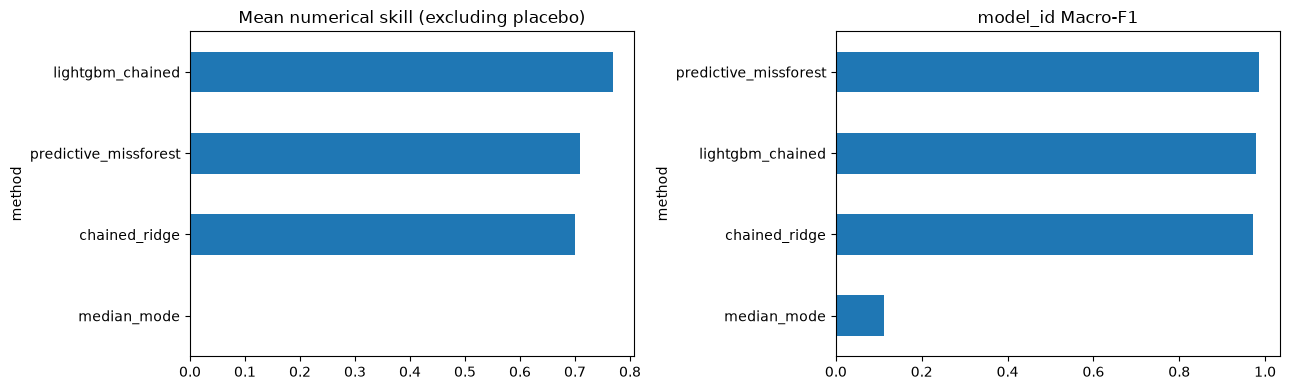

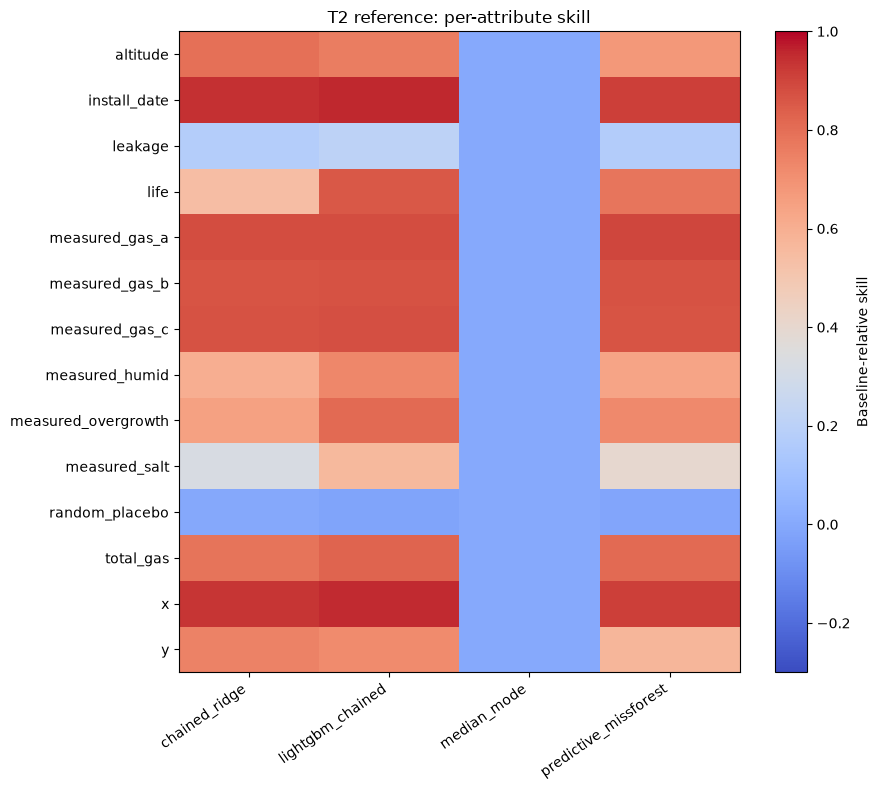

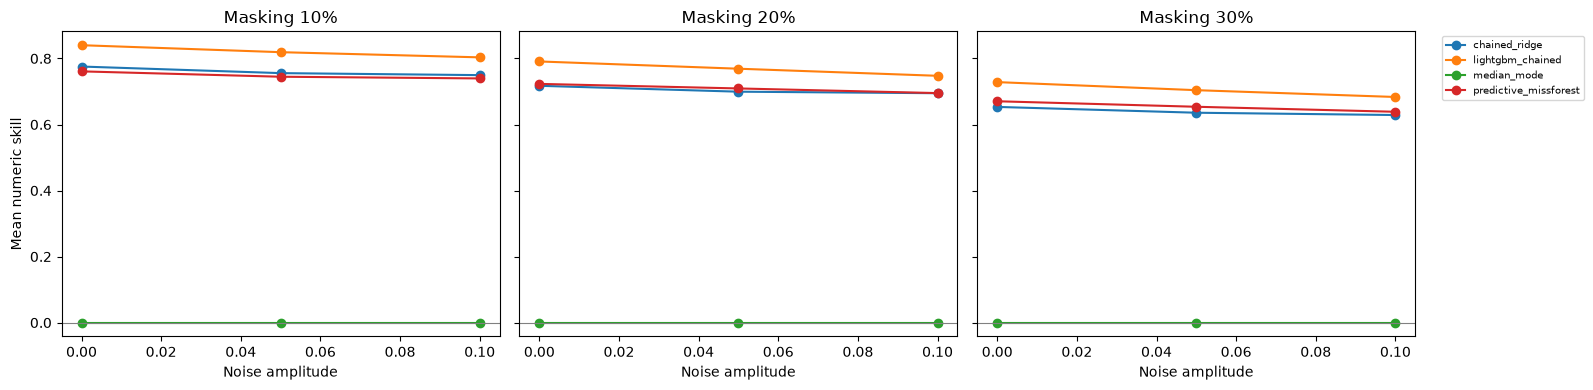

In [17]:
def spatial_bootstrap_skill(cells, reps=BOOTSTRAP_RESAMPLES, seed=MODEL_SEED):
    # Within one fitted scenario, resample spatial blocks (not individual cells).
    # Correctly recompute MAE ratios for each resample; cannot replace generator repeats.
    if cells.empty or cells['variable'].iloc[0] not in NUMERIC:return (np.nan,np.nan,np.nan)
    tmp=cells.copy()
    tmp['block']=tmp.x_tile.astype(str)+'_'+tmp.y_tile.astype(str)
    per=tmp.groupby('block').agg(err=('absolute_error','sum'),
             base=('baseline_absolute_error','sum'),n=('absolute_error','size'))
    if len(per)<2:return (np.nan,np.nan,np.nan)
    rng=np.random.default_rng(seed)
    draws=rng.integers(len(per),size=(reps,len(per)))
    arr=per[['err','base','n']].to_numpy(dtype=float)
    ae=arr[draws,0].sum(axis=1);be=arr[draws,1].sum(axis=1)
    valid=be>0
    skill=np.where(valid,1-ae/np.where(valid,be,1),np.nan)
    return (float(np.nanquantile(skill,.025)),float(np.nanmedian(skill)),float(np.nanquantile(skill,.975)))

def save_chart(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR/f'{name}.png',dpi=170,bbox_inches='tight')
    plt.show()

if not METRICS.empty:
    model_anchor=METRICS[(METRICS.experiment=='T2') &
       (METRICS.protocol=='unseen_records') &
       (METRICS.condition==f'mask{ANCHOR_MASK:.2f}_noise{ANCHOR_NOISE:.2f}')].copy()
    if not model_anchor.empty:
        anchor_summary=model_anchor.groupby('method').apply(lambda d: pd.Series({
           'mean_numeric_skill':d.loc[(d.type=='numeric')&(d.variable!='random_placebo'),'skill'].mean(),
           'median_numeric_skill':d.loc[(d.type=='numeric')&(d.variable!='random_placebo'),'skill'].median(),
           'placebo_skill':d.loc[d.variable=='random_placebo','skill'].mean(),
           'model_id_macro_f1':d.loc[d.variable=='model_id','macro_f1'].mean()}),include_groups=False)
        display(anchor_summary.sort_values('mean_numeric_skill',ascending=False))
        anchor_summary.to_csv(REPORT_DIR/'reference_model_summary.csv')
        fig,axs=plt.subplots(1,2,figsize=(13,4))
        anchor_summary.mean_numeric_skill.sort_values().plot.barh(ax=axs[0]);axs[0].set_title('Mean numerical skill (excluding placebo)')
        anchor_summary.model_id_macro_f1.sort_values().plot.barh(ax=axs[1]);axs[1].set_title('model_id Macro-F1')
        save_chart('reference_model_comparison')
        nums=model_anchor[model_anchor.type=='numeric']
        pivot=nums.pivot_table(index='variable',columns='method',values='skill')
        fig,ax=plt.subplots(figsize=(max(9,len(pivot.columns)*1.7),8))
        im=ax.imshow(pivot.values,cmap='coolwarm',vmin=-.3,vmax=1,aspect='auto')
        ax.set_xticks(range(len(pivot.columns)),pivot.columns,rotation=35,ha='right')
        ax.set_yticks(range(len(pivot.index)),pivot.index)
        fig.colorbar(im,ax=ax,label='Baseline-relative skill');ax.set_title('T2 reference: per-attribute skill')
        save_chart('reference_per_attribute_heatmap')
    t2=METRICS[(METRICS.experiment=='T2') & (METRICS.protocol=='unseen_records') &
               (METRICS.type=='numeric') & (METRICS.variable!='random_placebo')].copy()
    if t2.shape[0]:
        curve=t2.groupby(['method','mask_rate','noise'],as_index=False)['skill'].mean()
        fig,axs=plt.subplots(1,3,figsize=(16,4),sharey=True)
        for ax,mask in zip(axs,MASK_RATES):
            subset=curve[np.isclose(curve.mask_rate,mask)]
            for method,data in subset.groupby('method'):
                ax.plot(data.noise,data.skill,marker='o',label=method)
            ax.axhline(0,color='grey',lw=.8);ax.set_title(f'Masking {mask:.0%}');ax.set_xlabel('Noise amplitude')
        axs[0].set_ylabel('Mean numeric skill');axs[-1].legend(fontsize=7,bbox_to_anchor=(1.05,1))
        save_chart('t2_noise_masking_curves')
        # Per-attribute deterioration: how many targets keep positive observed skill?
        summary=t2.assign(advantage=t2.skill>0).groupby(['method','mask_rate','noise'],as_index=False).advantage.sum()
        summary.to_csv(REPORT_DIR/'t2_attribute_advantage_counts.csv',index=False)

## 12A - Attribute families and paired split comparisons

The complete-data supervised benchmark is **not a ceiling**. Summary means describe this generator only; paired comparisons use differences from the *same* split, not a universal ±0.014 threshold.

In [18]:
RELATIONSHIP_GROUPS={
    'x':'exact_or_inverse','y':'exact_or_inverse','altitude':'exact_or_inverse',
    'measured_overgrowth':'exact_or_inverse','total_gas':'exact_or_inverse',
    'life':'conditional_exact','install_date':'generator_shortcut',
    'measured_humid':'probabilistic','measured_salt':'probabilistic',
    'measured_gas_a':'probabilistic','measured_gas_b':'probabilistic','measured_gas_c':'probabilistic',
    'leakage':'inverse_inference','random_placebo':'independent_negative_control',
    'model_id':'redundantly_identifiable_categorical'}
REFERENCE=METRICS[(METRICS.experiment=='T2')&(METRICS.protocol=='unseen_records') &
                  (METRICS.condition==f'mask{ANCHOR_MASK:.2f}_noise{ANCHOR_NOISE:.2f}')].copy()
if len(REFERENCE):
    REFERENCE['relationship_group']=REFERENCE.variable.map(RELATIONSHIP_GROUPS)
    REFERENCE.sort_values(['variable','method']).to_csv(REPORT_DIR/'attribute_wise_reference.csv',index=False)
    numeric=REFERENCE[(REFERENCE.type=='numeric')&(REFERENCE.variable!='random_placebo')]
    family=numeric.groupby(['method','relationship_group'],as_index=False).skill.mean()
    family.to_csv(REPORT_DIR/'relationship_group_skill.csv',index=False)
    display(family.pivot(index='relationship_group',columns='method',values='skill').round(3))

# Repeat comparisons use *paired method differences* on each of the 3 held-out splits.
selection=METRICS[((METRICS.experiment=='T2') & (METRICS.protocol=='unseen_records') &
      METRICS.condition.eq(f'mask{ANCHOR_MASK:.2f}_noise{ANCHOR_NOISE:.2f}')) |
      (METRICS.experiment=='REPEAT')]
selection=selection[(selection.type=='numeric')&(selection.variable!='random_placebo')].copy()
selection['split_id']=np.where(selection.experiment=='REPEAT',selection.condition, f'repeated_split_{SPLIT_SEED}')
per_split=selection.groupby(['split_id','method'],as_index=False).skill.mean()
paired=per_split.pivot(index='split_id',columns='method',values='skill')
if {'lightgbm_chained','predictive_missforest'}.issubset(paired.columns):
    from scipy.stats import t as student_t
    differences=[]
    for method in ['lightgbm_chained','chained_ridge']:
        if method not in paired:continue
        v=(paired[method]-paired['predictive_missforest']).dropna()
        if len(v)<2:continue
        halfwidth=float(student_t.ppf(.975,len(v)-1)*v.std(ddof=1)/np.sqrt(len(v)))
        differences.append({'comparison':f'{method} − predictive_missforest',
                            'mean_paired_skill_difference':float(v.mean()),
                            'ci_lower':float(v.mean()-halfwidth),'ci_upper':float(v.mean()+halfwidth),
                            'sign_stable':bool((v>0).all() or (v<0).all()),
                            'n_spatial_splits':len(v),'only_one_generator_population':True})
    if differences:
        DIFFS=pd.DataFrame(differences)
        display(DIFFS)
        DIFFS.to_csv(REPORT_DIR/'paired_method_split_comparisons.csv',index=False)

method,chained_ridge,lightgbm_chained,median_mode,predictive_missforest
relationship_group,,,,
conditional_exact,0.542,0.854,0.0,0.780
exact_or_inverse,0.780,0.813,0.0,0.739
generator_shortcut,0.941,0.957,0.0,0.913
inverse_inference,0.176,0.209,0.0,0.168
probabilistic,0.707,0.782,0.0,0.733


,comparison,mean_paired_skill_difference,ci_lower,ci_upper,sign_stable,n_spatial_splits,only_one_generator_population
0,lightgbm_chained − predictive_missforest,0.059982,0.044244,0.075721,True,3,True
1,chained_ridge − predictive_missforest,-0.005201,-0.024211,0.013808,False,3,True


## 12B - Paired method-difference bootstrap (same scored cells)

In [19]:
# Paired spatial-block bootstrap of method *differences* on identical scored cells.
# This is separate from the CI for the skill of one method; neither measures generator variation.
if not CELLS.empty:
    anchor=CELLS[(CELLS.experiment=='T2')&
        (CELLS.protocol=='unseen_records')&
        (CELLS.condition==f'mask{ANCHOR_MASK:.2f}_noise{ANCHOR_NOISE:.2f}')&
        CELLS.variable.isin(NUMERIC) & CELLS.variable.ne('random_placebo')].copy()
    differences=[]
    for other in ['lightgbm_chained','chained_ridge']:
        left=anchor[anchor.method==other]
        right=anchor[anchor.method=='predictive_missforest']
        for target in NUMERIC:
            if target=='random_placebo':continue
            a=left[left.variable==target][['row_position','x_tile','y_tile','absolute_error','baseline_absolute_error']]
            b=right[right.variable==target][['row_position','absolute_error','baseline_absolute_error']]
            paired=a.merge(b,on='row_position',suffixes=('_a','_b'),validate='one_to_one')
            if len(paired)<2:continue
            if not np.allclose(paired.baseline_absolute_error_a,paired.baseline_absolute_error_b,rtol=1e-10,atol=1e-8):
                raise AssertionError('Paired methods do not share the same marginal baseline cells')
            paired['block']=paired.x_tile.astype(str)+'_'+paired.y_tile.astype(str)
            groups=paired.groupby('block')[['absolute_error_a','absolute_error_b','baseline_absolute_error_a']].sum()
            values=groups.to_numpy(dtype=float)
            rng=np.random.default_rng(MODEL_SEED+17)
            ids=rng.integers(0,len(values),size=(BOOTSTRAP_RESAMPLES,len(values)))
            sums=values[ids].sum(axis=1)
            valid=sums[:,2]>0
            # Skill(other) - skill(PMF) = (PMF absolute error - other absolute error) / baseline absolute error.
            d=(sums[valid,1]-sums[valid,0])/sums[valid,2]
            if not len(d):continue
            differences.append({'method_a':other,'method_b':'predictive_missforest','variable':target,
                'paired_cells':len(paired),'spatial_blocks':len(values),
                'skill_difference':float((values[:,1].sum()-values[:,0].sum())/values[:,2].sum()),
                'ci_lower':float(np.quantile(d,.025)),'ci_upper':float(np.quantile(d,.975)),
                'within_one_fitted_split_only':True})
    if differences:
        paired_ci=pd.DataFrame(differences)
        paired_ci.to_csv(REPORT_DIR/'paired_spatial_block_method_differences.csv',index=False)
        display(paired_ci.sort_values('skill_difference',ascending=False).head(12))

,method_a,method_b,variable,paired_cells,spatial_blocks,skill_difference,ci_lower,ci_upper,within_one_fitted_split_only
14,chained_ridge,predictive_missforest,y,413,20,0.168454,0.107800,0.223197,True
5,lightgbm_chained,predictive_missforest,measured_salt,386,20,0.161854,0.124238,0.190757,True
1,lightgbm_chained,predictive_missforest,y,413,20,0.145440,0.097452,0.187920,True
16,chained_ridge,predictive_missforest,altitude,409,20,0.116331,0.054931,0.191378,True
4,lightgbm_chained,predictive_missforest,measured_humid,409,20,0.092361,0.070112,0.115363,True
3,lightgbm_chained,predictive_missforest,altitude,409,20,0.085504,0.051651,0.117428,True
6,lightgbm_chained,predictive_missforest,measured_overgrowth,392,20,0.082220,0.051093,0.112948,True
7,lightgbm_chained,predictive_missforest,life,393,20,0.074047,0.055953,0.090933,True
2,lightgbm_chained,predictive_missforest,install_date,392,20,0.043744,0.029634,0.064425,True
0,lightgbm_chained,predictive_missforest,x,394,20,0.042596,0.029429,0.064255,True


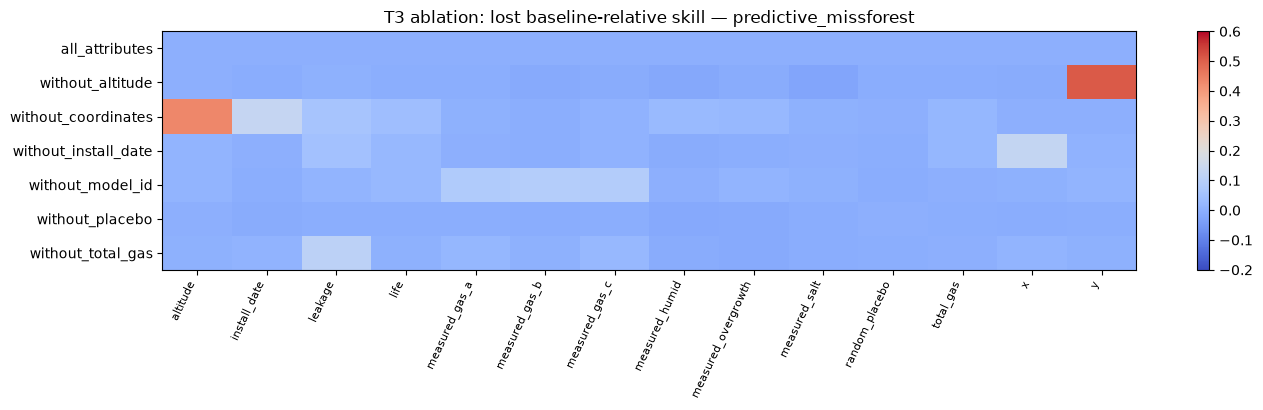

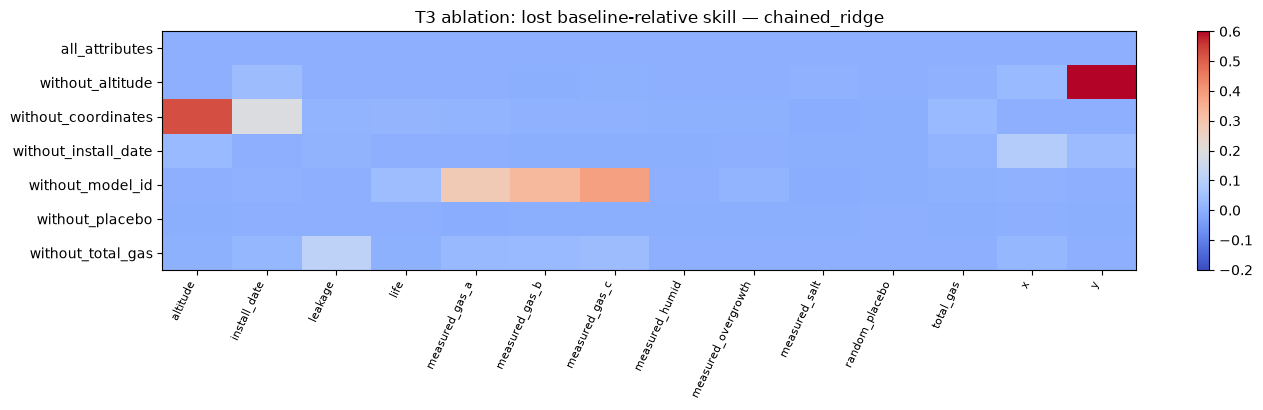

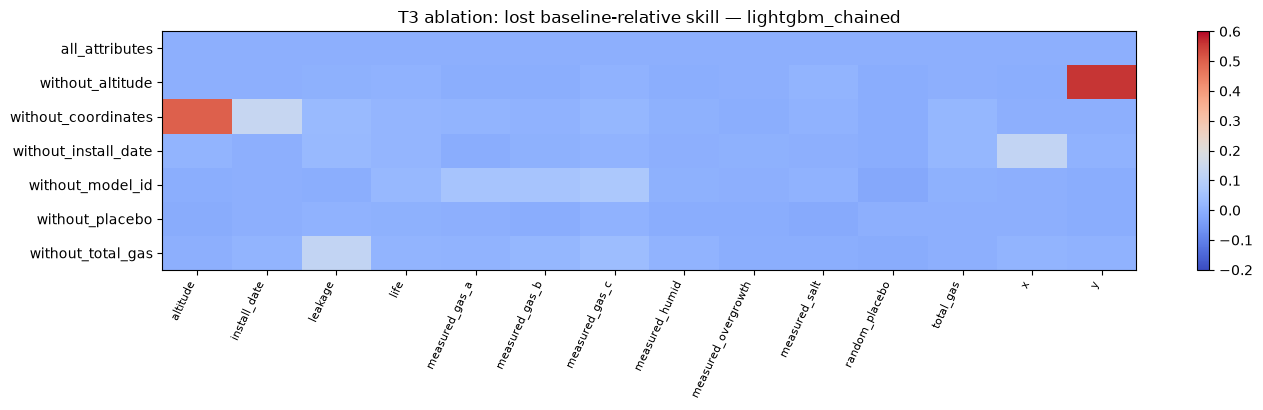

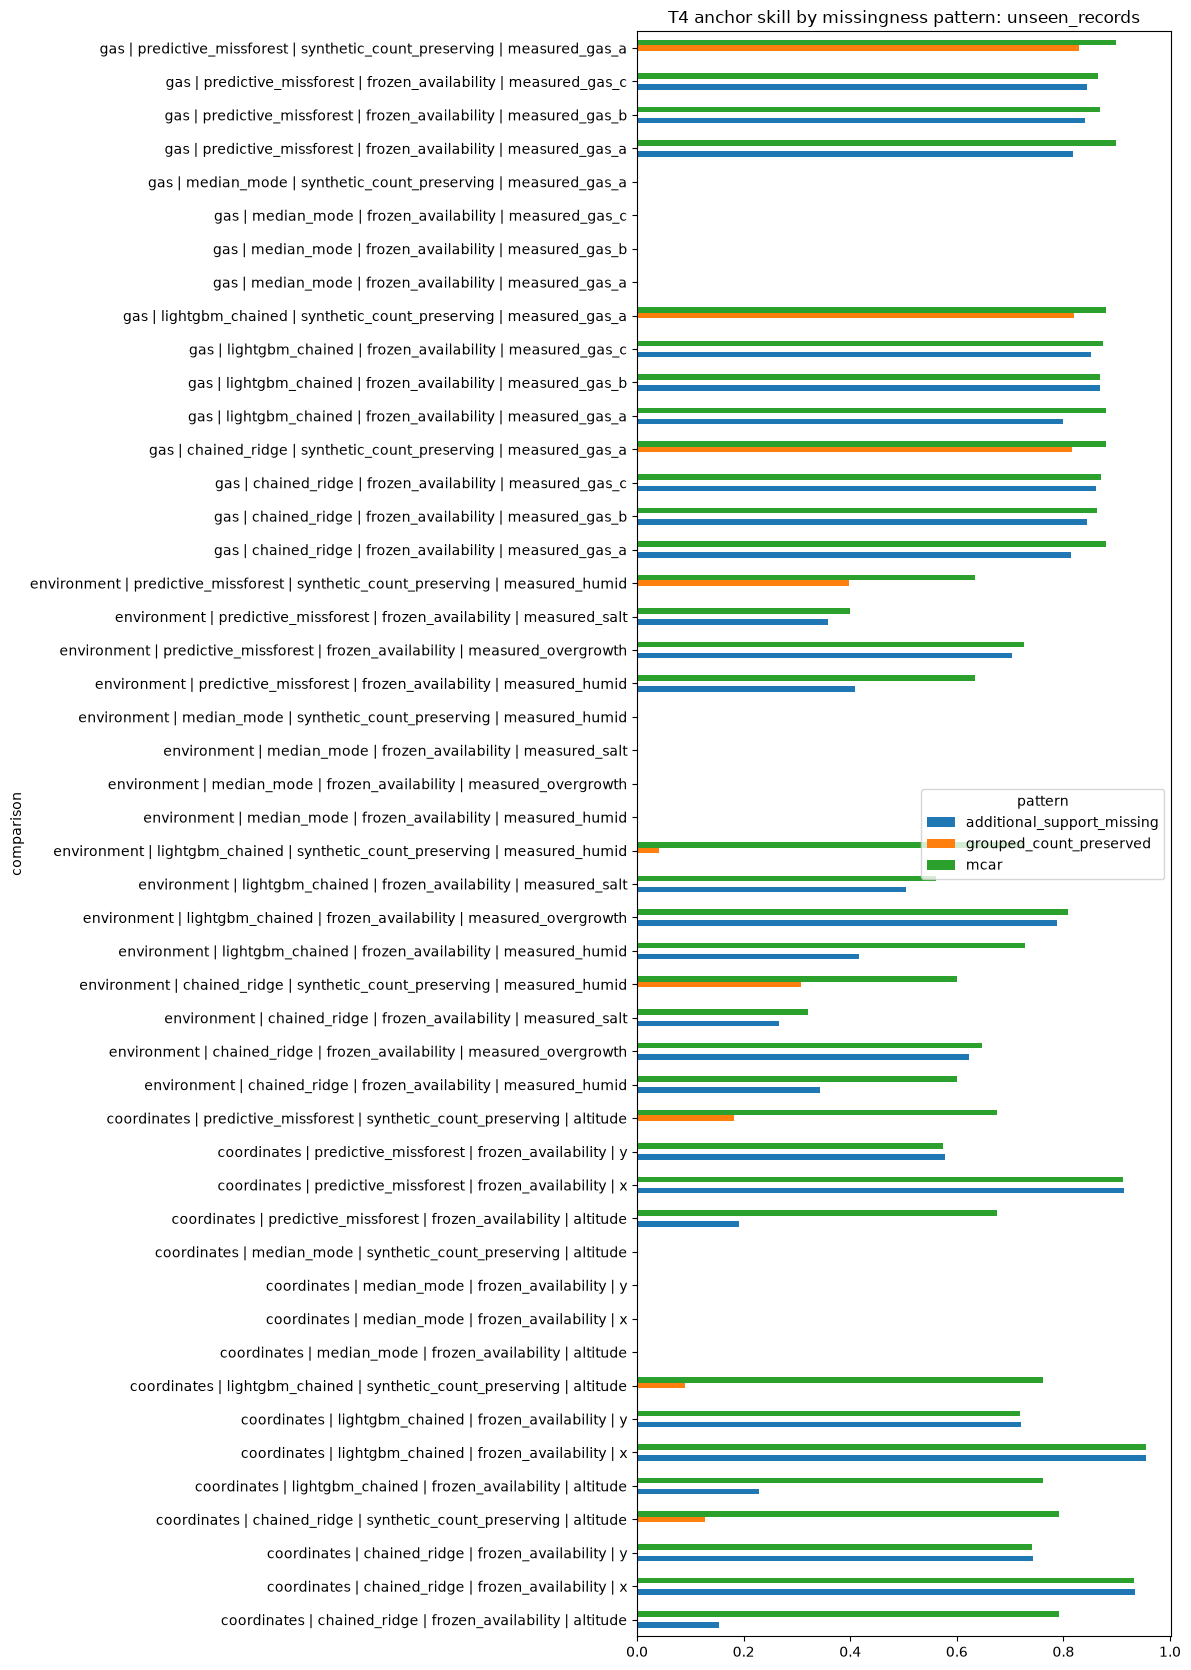

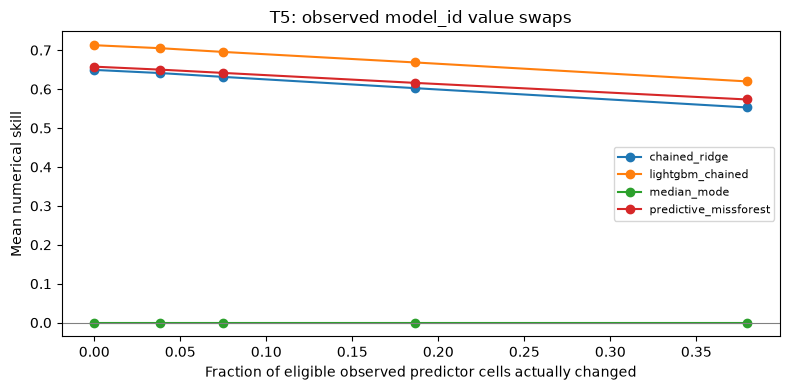

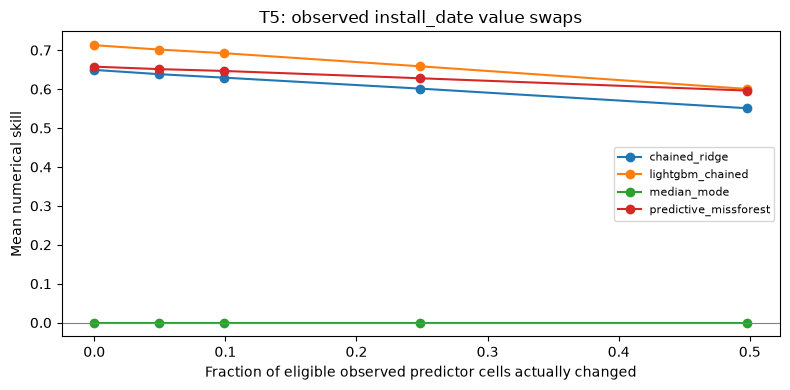

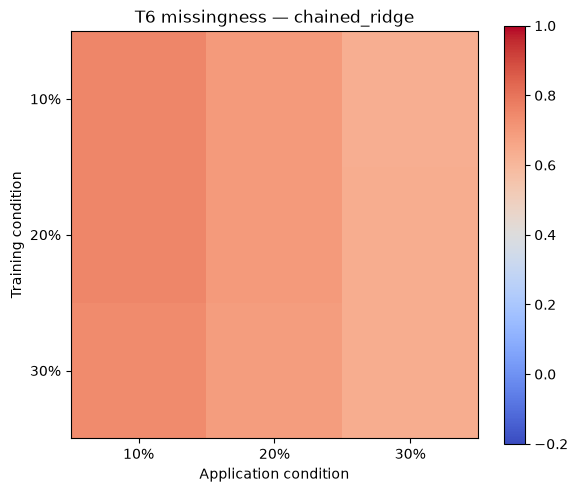

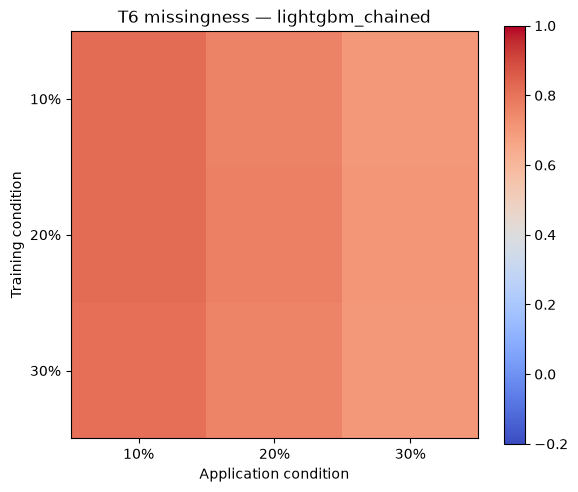

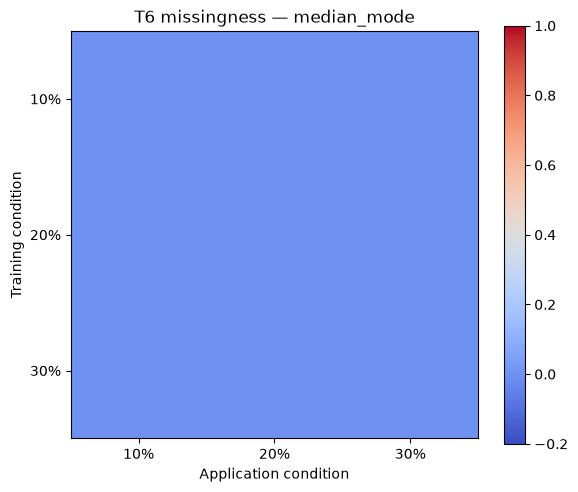

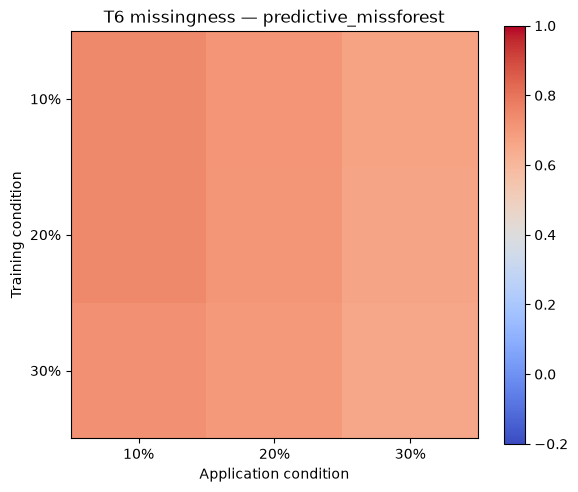

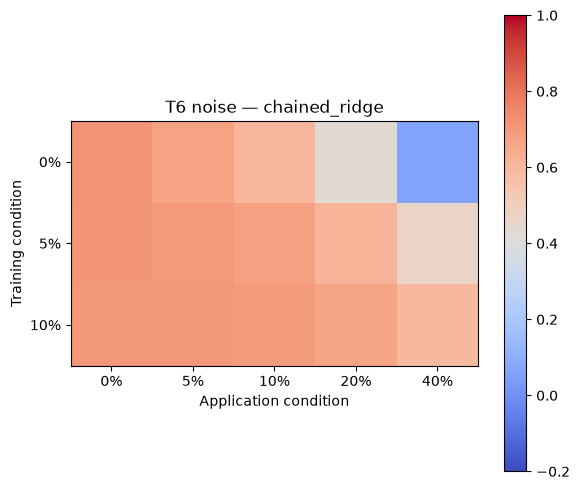

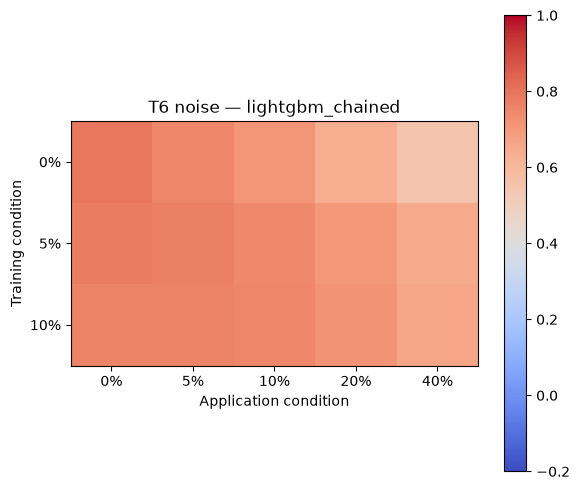

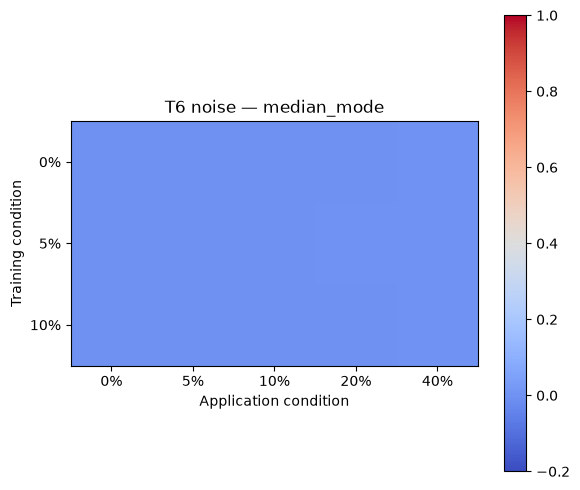

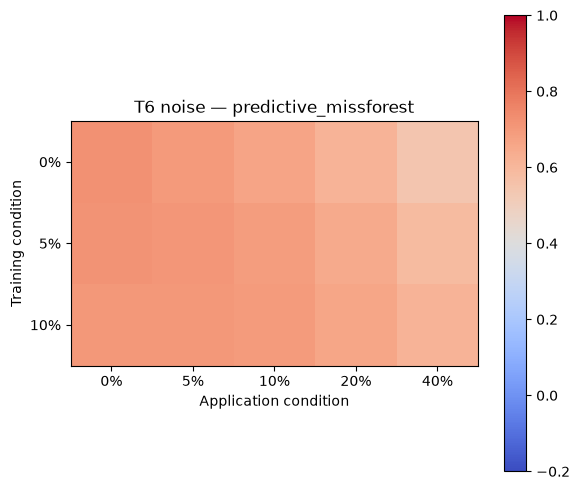

In [20]:
if not METRICS.empty:
    t3=METRICS[(METRICS.experiment=='T3')&(METRICS.type=='numeric')].copy()
    if len(t3):
        full=t3[t3.condition=='all_attributes'][['method','variable','mae','baseline_mae']].rename(columns={'mae':'full_mae','baseline_mae':'full_baseline_mae'})
        impact=t3.merge(full,on=['method','variable'])
        # Positive change means removing predictors worsened the target.
        impact['delta_skill_lost']=(impact.mae-impact.full_mae)/impact.full_baseline_mae
        impact.to_csv(REPORT_DIR/'t3_ablation_skill_loss.csv',index=False)
        for method in impact.method.unique():
            table=impact[impact.method==method].pivot_table(index='condition',columns='variable',values='delta_skill_lost')
            if len(table)==0:continue
            fig,ax=plt.subplots(figsize=(max(12,len(table.columns)),max(4,len(table)*.6)))
            im=ax.imshow(table.fillna(0).values,cmap='coolwarm',aspect='auto',vmin=-.2,vmax=.6)
            ax.set_xticks(range(len(table.columns)),table.columns,rotation=65,ha='right',fontsize=8)
            ax.set_yticks(range(len(table)),table.index)
            ax.set_title(f'T3 ablation: lost baseline-relative skill — {method}')
            fig.colorbar(im,ax=ax);save_chart(f't3_ablation_{method}')
    t4=METRICS[(METRICS.experiment=='T4') & (METRICS.type=='numeric')].copy()
    if len(t4):
        for protocol,data in t4.groupby('protocol'):
            x=data[(data.get('pattern').isin(['mcar','additional_support_missing','grouped_count_preserved'])) &
                   data.get('group').notna()].copy()
            if x.empty:continue
            x['comparison']=x['group'].astype(str)+' | '+x['method'].astype(str)+' | '+x['t4_design'].astype(str)+' | '+x['variable'].astype(str)
            pivot=x.pivot_table(index='comparison',columns='pattern',values='skill',aggfunc='first')
            if pivot.empty:continue
            fig,ax=plt.subplots(figsize=(12,max(4,len(pivot)*.35)))
            pivot.plot.barh(ax=ax);ax.axvline(0,color='grey',lw=.6)
            ax.set_title(f'T4 anchor skill by missingness pattern: {protocol}')
            save_chart(f't4_{protocol}')
    t5=METRICS[(METRICS.experiment=='T5') & METRICS.get('prevalence',pd.Series(index=METRICS.index)).notna() &
               (METRICS.type=='numeric')].copy()
    if len(t5):
        for predictor in T5_PREDICTORS:
            x=t5[(t5.predictor==predictor)&(t5.condition.astype(str).str.contains('swap_'))]
            if not len(x):continue
            # Summarise paired dose effect across numeric targets.
            plot=x.groupby(['method','effective_prevalence'],as_index=False).skill.mean()
            fig,ax=plt.subplots(figsize=(8,4))
            for method,g in plot.groupby('method'):
                ax.plot(g.effective_prevalence,g.skill,marker='o',label=method)
            ax.axhline(0,color='grey',lw=.8);ax.set_title(f'T5: observed {predictor} value swaps')
            ax.set_xlabel('Fraction of eligible observed predictor cells actually changed');ax.set_ylabel('Mean numerical skill')
            ax.legend(fontsize=8);save_chart(f't5_dose_{predictor}')
    t6=METRICS[(METRICS.experiment=='T6')&(METRICS.type=='numeric')&(METRICS.variable!='random_placebo')].copy()
    if len(t6):
        for shift,x in t6.groupby('shift_type'):
            for method,g in x.groupby('method'):
                if shift=='noise':
                    a,b='train_noise','apply_noise'
                else:a,b='train_mask','apply_mask'
                pivot=g.groupby([a,b]).skill.mean().unstack()
                fig,ax=plt.subplots(figsize=(6,5));im=ax.imshow(pivot.values,cmap='coolwarm',vmin=-.2,vmax=1)
                ax.set_xticks(range(len(pivot.columns)),[f'{v:.0%}' for v in pivot.columns]);ax.set_xlabel('Application condition')
                ax.set_yticks(range(len(pivot.index)),[f'{v:.0%}' for v in pivot.index]);ax.set_ylabel('Training condition')
                ax.set_title(f'T6 {shift} — {method}');fig.colorbar(im,ax=ax)
                save_chart(f't6_{shift}_{method}')
    if 'RUN_LOG' in globals() and len(RUN_LOG):
        rt=pd.DataFrame(RUN_LOG)
        rt.groupby(['experiment','method'])[['fit_seconds','apply_seconds']].sum().fillna(0).to_csv(REPORT_DIR/'runtime_by_experiment.csv')

## 13 - Per-cell uncertainty, propagation and interpretation tables

In [21]:
if not CELLS.empty:
    anchor_cells=CELLS[(CELLS.experiment=='T2')&(CELLS.protocol=='unseen_records')&
         (CELLS.condition==f'mask{ANCHOR_MASK:.2f}_noise{ANCHOR_NOISE:.2f}') &
         (CELLS.variable.isin(NUMERIC))]
    intervals=[]
    for (method,target),group in anchor_cells.groupby(['method','variable']):
        lo,mid,hi=spatial_bootstrap_skill(group)
        intervals.append({'method':method,'variable':target,'ci_lower':lo,'ci_median':mid,'ci_upper':hi,
                          'n_spatial_blocks':group[['x_tile','y_tile']].drop_duplicates().shape[0]})
    CI=pd.DataFrame(intervals)
    if not CI.empty:
        CI.to_csv(REPORT_DIR/'reference_block_bootstrap.csv',index=False)
        display(CI.head(12))
        CI['advantage_tier']=np.select([CI.ci_lower>0,CI.ci_upper<0],
                                      ['advantage_retained','worse_than_baseline'],
                                      default='advantage_not_demonstrated')
        display(CI.pivot_table(index='method',columns='advantage_tier',values='variable',aggfunc='count',fill_value=0))
    # T5 paired difference: compare same row+target+method at 0% and nonzero corruption.
    t5cells=CELLS[(CELLS.experiment=='T5') & CELLS.get('predictor',pd.Series(index=CELLS.index)).notna()].copy()
    propagation=[]
    for predictor in T5_PREDICTORS:
        grp=t5cells[t5cells.predictor==predictor]
        zeros=grp[grp.condition==f'{predictor}_swap_0.00'][['method','variable','row_position','absolute_error']].rename(columns={'absolute_error':'error_at_zero'})
        comp=grp[grp.get('prevalence',pd.Series(index=grp.index)).fillna(0)>0].merge(zeros,
               on=['method','variable','row_position'],how='inner')
        if comp.empty:continue
        comp['paired_change_in_absolute_error']=comp.absolute_error-comp.error_at_zero
        for key,subset in comp.groupby(['method','variable','prevalence','predictor_corrupted_in_row'],dropna=False):
            propagation.append(dict(zip(['method','variable','prevalence','predictor_corrupted_in_row'],key),
                                    predictor=predictor,mean_paired_error_change=subset.paired_change_in_absolute_error.mean(),
                                    n_cells=len(subset)))
    propagation=pd.DataFrame(propagation)
    if len(propagation):
        propagation.to_csv(REPORT_DIR/'t5_error_propagation.csv',index=False)
        display(propagation.sort_values('mean_paired_error_change',ascending=False).head(15))

if not METRICS.empty:
    important=['install_date','altitude','measured_gas_a','measured_gas_b','measured_gas_c',
               'life','measured_salt','leakage','random_placebo','model_id']
    # Practical RQ3 summary: report-model performance + generator-known parent features.
    parents={'altitude':'x, y (exact identity)',
         'install_date':'grid ordering shortcut via x, y',
         'measured_gas_a':'model_id, install_date, leakage (total_gas is a derived sibling, not generator parent)',
         'measured_gas_b':'model_id, install_date, leakage (total_gas is a derived sibling, not generator parent)',
         'measured_gas_c':'model_id, install_date, leakage (total_gas is a derived sibling, not generator parent)',
         'life':'model_id, install_date, hazards, total_gas',
         'measured_salt':'y and independent random factor',
         'leakage':'independent generator draw U(0.8, 1.2); inverse prediction via gas channels, model_id and date',
         'random_placebo':'independent negative control',
         'model_id':'redundant pathways: gas patterns, date bands and model-dependent life; marginal relevance requires joint ablation'}
    interpretation=model_anchor[model_anchor.variable.isin(important)][['method','variable','skill','macro_f1']].copy() if 'model_anchor' in globals() else pd.DataFrame()
    if len(interpretation):
        interpretation['generator_relationship']=interpretation.variable.map(parents)
        interpretation.to_csv(REPORT_DIR/'rq3_relationship_evidence.csv',index=False)
        display(interpretation.head(15))

,method,variable,ci_lower,ci_median,ci_upper,n_spatial_blocks
0,chained_ridge,altitude,0.751353,0.791074,0.829158,20
1,chained_ridge,install_date,0.924522,0.941337,0.956652,20
2,chained_ridge,leakage,0.105071,0.174588,0.245061,20
3,chained_ridge,life,0.403515,0.539649,0.632579,20
4,chained_ridge,measured_gas_a,0.862183,0.880095,0.898342,20
5,chained_ridge,measured_gas_b,0.838591,0.863443,0.884619,20
6,chained_ridge,measured_gas_c,0.842849,0.870281,0.890538,20
7,chained_ridge,measured_humid,0.548156,0.599277,0.643340,20
8,chained_ridge,measured_overgrowth,0.590836,0.646008,0.691149,20
9,chained_ridge,measured_salt,0.257035,0.318187,0.379326,20


advantage_tier,advantage_not_demonstrated,advantage_retained,worse_than_baseline
method,,,
chained_ridge,1,13,0
lightgbm_chained,1,13,0
median_mode,14,0,0
predictive_missforest,0,13,1


,method,variable,prevalence,predictor_corrupted_in_row,predictor,mean_paired_error_change,n_cells
159,lightgbm_chained,measured_gas_b,0.10,True,model_id,1683.515219,23
157,lightgbm_chained,measured_gas_b,0.05,True,model_id,1644.579866,10
55,chained_ridge,measured_gas_c,0.50,True,model_id,1583.006800,123
171,lightgbm_chained,measured_gas_c,0.50,True,model_id,1536.898883,123
163,lightgbm_chained,measured_gas_b,0.50,True,model_id,1525.205911,111
149,lightgbm_chained,measured_gas_a,0.05,True,model_id,1455.714572,11
155,lightgbm_chained,measured_gas_a,0.50,True,model_id,1442.714334,116
43,chained_ridge,measured_gas_b,0.10,True,model_id,1417.632926,23
151,lightgbm_chained,measured_gas_a,0.10,True,model_id,1357.615670,22
51,chained_ridge,measured_gas_c,0.10,True,model_id,1304.372614,25


,method,variable,skill,macro_f1,generator_relationship
662,median_mode,install_date,0.000000,NaN,"grid ordering shortcut via x, y"
663,median_mode,model_id,NaN,0.112689,"redundant pathways: gas patterns, date bands a..."
664,median_mode,altitude,0.000000,NaN,"x, y (exact identity)"
666,median_mode,measured_salt,0.000000,NaN,y and independent random factor
668,median_mode,life,0.000000,NaN,"model_id, install_date, hazards, total_gas"
669,median_mode,random_placebo,0.000000,NaN,independent negative control
670,median_mode,measured_gas_a,0.000000,NaN,"model_id, install_date, leakage (total_gas is ..."
671,median_mode,measured_gas_b,0.000000,NaN,"model_id, install_date, leakage (total_gas is ..."
672,median_mode,measured_gas_c,0.000000,NaN,"model_id, install_date, leakage (total_gas is ..."
674,median_mode,leakage,0.000000,NaN,"independent generator draw U(0.8, 1.2); invers..."


## 14 - Scientific interpretation boundaries

- **T2:** Compare the same method within each protocol. A transductive table has access to the held-out rows' *observed* values during fitting; a held-out fit does not. The protocol gap also changes training size. Higher aggregate skill can be dominated by deterministic/shortcut attributes.
- **T3:** Feature ablation with refitting measures value of available information (including indirect iterative effects), not whether the fitted model *causally uses* a feature or whether that attribute causes real transformer behaviour. `without_placebo` is a null ablation. The PMF seed-preservation adapter changes only the notebook's ablation fits.
- **T4 primary:** Additional co-missing predictor cells **increase** overall masking; only anchor target cells remain matched. Call it a frozen-model *predictor-availability intervention*, not a constant-missing-rate comparison.
- **T4 secondary:** Grouped masks match **per-column missing counts** and anchor scoring positions, but re-exposed cells are synthetically simulated from truth and new noise draws. This changes the fitting data and model and is conceptually distinct from the frozen primary treatment.
- **T5:** Value swaps preserve ranges and marginal distributions but can violate synthetic structural relationships. Error propagation is computed by paired differences for the **same test row/target**, separating corrupted-predictor rows from other rows; comparing the raw errors of those two populations would be confounded.
- **T6:** The same trained imputer is applied to different observed-input noise/missingness conditions. Above ±10%, the noise is a controlled extrapolation of the generator's existing random draws, not additional supplied SAPN data. A worse frozen model does not establish that retraining always helps; compare within each application condition.
- **MICE-PMM:** Mean- and median-pooled MICE point estimates are evaluated on the same stochastic draws. Mean pooling is the reported primary benchmark because it achieved better numerical skill in this study; median pooling provides a sensitivity comparison. The teammate's algorithm performs multiple stochastic completed tables and is **transductive**. The mean/mode aggregated completion is a convenient point-estimate benchmark and does not replace proper pooled downstream multiple-imputation inference. Do not compare its joint-table scores with inductive scores as if protocols matched.
- **Uncertainty:** The spatial-block bootstrap is conditional on the chosen fitted models, masks and synthetic population. Repeated spatial splits assess split stability; independent generator seeds require newly generated populations and are not supplied by this dataset archive.
- **Breakdown:** `skill < 0` means a worse point estimate than Median/Mode. Report a statistically supported disadvantage only when the paired uncertainty interval is wholly below zero; do not infer a threshold beyond tested severity. Categorical results are reported through Macro-F1 and balanced accuracy (not a numerical-skill definition).
- **TabPFN:** excluded from this notebook. The prior separate TabPFN imputation experiments and results remain available under the original archive/output directories.

**Main files to use for the report:** `all_per_target_metrics.csv`, `all_masked_cells.csv`, `reference_model_summary.csv`, `reference_block_bootstrap.csv`, `t3_ablation_skill_loss.csv`, `t5_error_propagation.csv`, `rq3_relationship_evidence.csv`, the T4 per-group mask logs and the `figures/` directory.

**Interpretation of additional analyses:** Paired comparison uncertainty is target/comparison-specific; there is no universal ±0.014 tolerance. Additional row-matched T4 controls quantify dependence on *which* predictors disappear while holding missing count per affected record fixed. Predictor ablation with refitting does not prove direct model reliance; joint ablations expose redundant paths. The completed synthetic population is seed 219; `pipeline/data/transformers` contains a different generated population of unrecorded seed and is not silently pooled. No theoretical recoverability ceilings are claimed.


**Execution guide:** `EXECUTE_EXPERIMENTS=True` runs the study on the supplied data; use `MODE='quick'` to test the setup or `MODE='full'` to reproduce the research configurations. `RUN_RELATIONSHIP_EXPERIMENTS=True` executes the joint ablation, matched-volume controls and conditional-life analysis. To analyse saved results without model fitting, use `EXECUTE_EXPERIMENTS=False`, set `RESULTS_SOURCE_DIR` and disable the relationship experiments. For a separate MICE pooling comparison against saved results, enable `RUN_MICE_POOLING_COMPARISON=True` and `RUN_RELATIONSHIP_EXPERIMENTS=True`.
